**Optimizing Marketing Strategies based on Regional Product Trends in a Super App Company through Time Series Forecasting**

**Rebecca Yulyartha Bulawan Sihombing**



**Data Import**

In [ ]:
# %pip install --upgrade kaggle pandas

In [1]:
from pathlib import Path

folder = Path.home() / ".kaggle"
folder.mkdir(exist_ok=True)
(folder / "access_token").write_text("KGAT_e599a72de37d9da9e3a8ce4e8c90606c")
print("Token tersimpan di:", folder / "access_token")

Token tersimpan di: C:\Users\Rebecca YBS\.kaggle\access_token


In [2]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()
print("Terhubung ke Kaggle!")

Terhubung ke Kaggle!


In [3]:
datasets = api.dataset_list(search="transaction", user="rebeccasihombing")
for d in datasets:
    print(d.ref)

rebeccasihombing/data-transaction
rebeccasihombing/master-data-transaction


In [4]:
# Import library Panda
import pandas as pd
import os
from kaggle.api.kaggle_api_extended import KaggleApi

**Data File : trx**

In [5]:
#Read Dataframe untuk ditampilkan
directory = "data/"

if not os.path.exists(directory) or not os.listdir(directory):
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files("rebeccasihombing/data-transaction", path=directory, unzip=True)
    print("Download selesai.")
else:
    print("Data sudah ada, download dilewati.")

# 2. Baca dan gabungkan semua file CSV
files = sorted(f for f in os.listdir(directory) if f.endswith(".csv"))
dfs = []
rows = 0
print("Daftar file dalam direktori:")
for file in files:
    print(file)
    df = pd.read_csv(os.path.join(directory, file))
    rows += len(df)
    dfs.append(df)

main_trx = pd.concat(dfs, ignore_index=True)

print(f"Jumlah file : {len(files)}")
print(f"No of rows : {rows}, length of main: {len(main_trx)}")

Data sudah ada, download dilewati.
Daftar file dalam direktori:
11_processed.csv
12_processed.csv
13_processed.csv
14_processed.csv
15_processed.csv
16_processed.csv
17_processed.csv
18_processed.csv
19_processed.csv
21_processed.csv
31_processed.csv
32_processed.csv
33_processed.csv
34_processed.csv
35_processed.csv
36_processed.csv
51_processed.csv
52_processed.csv
53_processed.csv
61_processed.csv
62_processed.csv
63_processed.csv
64_processed.csv
65_processed.csv
71_processed.csv
72_processed.csv
73_processed.csv
74_processed.csv
75_processed.csv
76_processed.csv
81_processed.csv
82_processed.csv
91_processed.csv
92_processed.csv
93_processed.csv
94_processed.csv
95_processed.csv
96_processed.csv
99_processed.csv
Jumlah file : 39
No of rows : 12864324, length of main: 12864324


In [6]:
main_trx

,id,user_id,product_id,gross_amount,discounts,transaction_date,product_id
0,TRX630646,SC1105072002001,1.0,33900.0,NaN,8/3/2024,NaN
1,TRX630647,SC1105072002001,1.0,25900.0,NaN,8/21/2024,NaN
2,TRX630648,SC1105072002001,1.0,13900.0,4000.0,9/9/2024,NaN
3,TRX630649,SC1105072002001,1.0,56300.0,6000.0,3/19/2024,NaN
4,TRX630650,SC1105072002001,2.0,5400.0,NaN,7/5/2024,NaN
...,...,...,...,...,...,...,...
12864319,TRX912811,SC99BE010001002,NaN,10900.0,NaN,2024-12-18,12.0
12864320,TRX912812,SC99BE010001002,NaN,10400.0,NaN,2024-03-10,15.0
12864321,TRX912813,SC99BE010001002,NaN,100.0,NaN,2024-04-24,15.0
12864322,TRX912814,SC99BE010001002,NaN,4400.0,4400.0,2024-04-22,15.0


In [7]:
print([repr(c) for c in main_trx.columns])

["'id'", "'user_id'", "'product_id '", "'gross_amount'", "'discounts'", "'transaction_date'", "'product_id'"]


In [8]:
# rapikan nama kolom dulu
main_trx.columns = main_trx.columns.str.strip().str.lower()

# karena sekarang ada 2 kolom bernama sama, ambil secara posisi
pid = main_trx.loc[:, 'product_id']          # DataFrame berisi 2 kolom
merged_pid = pid.iloc[:, 0].combine_first(pid.iloc[:, 1])

main_trx = main_trx.drop(columns='product_id')
main_trx['product_id'] = merged_pid

In [9]:
main_trx['transaction_date'] = pd.to_datetime(
    main_trx['transaction_date'], format='mixed', errors='coerce'
)
print(main_trx['transaction_date'].isna().sum())

0


In [10]:
main_trx

,id,user_id,gross_amount,discounts,transaction_date,product_id
0,TRX630646,SC1105072002001,33900.0,NaN,2024-08-03,1.0
1,TRX630647,SC1105072002001,25900.0,NaN,2024-08-21,1.0
2,TRX630648,SC1105072002001,13900.0,4000.0,2024-09-09,1.0
3,TRX630649,SC1105072002001,56300.0,6000.0,2024-03-19,1.0
4,TRX630650,SC1105072002001,5400.0,NaN,2024-07-05,2.0
...,...,...,...,...,...,...
12864319,TRX912811,SC99BE010001002,10900.0,NaN,2024-12-18,12.0
12864320,TRX912812,SC99BE010001002,10400.0,NaN,2024-03-10,15.0
12864321,TRX912813,SC99BE010001002,100.0,NaN,2024-04-24,15.0
12864322,TRX912814,SC99BE010001002,4400.0,4400.0,2024-04-22,15.0


**Import Master Data**

In [11]:
directory = "data_master/"

# 1. Download seluruh isi dataset master (dilewati kalau sudah ada)
if not os.path.exists(directory) or not os.listdir(directory):
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files("rebeccasihombing/master-data-transaction", path=directory, unzip=True)
    print("Download selesai.")
else:
    print("Data master sudah ada, download dilewati.")

# 2. Baca tiap file ke DataFrame masing-masing
df_product = pd.read_csv(os.path.join(directory, "product_reference.csv"), delimiter=';')
df_loc     = pd.read_csv(os.path.join(directory, "location_reference.csv"))
df_user    = pd.read_csv(os.path.join(directory, "user.csv"))

# 3. Cek hasilnya
for nama, df in [("df_product", df_product), ("df_loc", df_loc), ("df_user", df_user)]:
    print(f"{nama}: {df.shape[0]} baris, {df.shape[1]} kolom")

Data master sudah ada, download dilewati.
df_product: 18 baris, 2 kolom
df_loc: 7407 baris, 6 kolom
df_user: 427486 baris, 8 kolom


**Data File : Product_references**

In [12]:
df_product

,id,product name
0,1,Man Fashion
1,2,Woman Fashion
2,3,Food & Drink
3,4,Ride Hailing
4,5,Keperluan Rumah Tangga
5,6,Travel
6,7,Keperluan Anak
7,8,Elektronik
8,9,Other
9,10,"Transportasi (Kereta, Pesawat, Kapal)"


In [13]:
df_loc

,nama provinsi,kode provinsi,nama kabupaten,kode kabupaten,nama kecamatan,kode kecamatan
0,GORONTALO,75,BOALEMO,7502,BOTUMOITO,750206
1,GORONTALO,75,BOALEMO,7502,DULUPI,750203
2,GORONTALO,75,BOALEMO,7502,MANANGGU,750205
3,GORONTALO,75,BOALEMO,7502,PAGUYAMAN,750201
4,GORONTALO,75,BOALEMO,7502,PAGUYAMAN PANTAI,750207
...,...,...,...,...,...,...
7402,SUMATERA UTARA,12,TOBA,1212,SIANTAR NARUMONDA,121220
7403,SUMATERA UTARA,12,TOBA,1212,SIGUMPAR,121219
7404,SUMATERA UTARA,12,TOBA,1212,SILAEN,121203
7405,SUMATERA UTARA,12,TOBA,1212,TAMPAHAN,121222


In [14]:
df_user

,id,full_name,gender,money_spent,refund,wallet_balance,join_date,birth
0,SC7502062007001,PRIYANTI FIORI,perempuan,2270000.0,130000.0,480000.0,2023-11-05,1984-07-25
1,SC7502062007002,KURNIA MUHAMAD WANIMBO,laki-laki,2370000.0,140000.0,500000.0,2023-12-27,1991-02-12
2,SC7502062007003,AJENG LESTARI,perempuan,0.0,0.0,0.0,2024-07-19,1982-06-18
3,SC7502062007004,TIA IRIANI S.E.,perempuan,0.0,0.0,0.0,2024-05-24,1972-09-27
4,SC7502062006001,ANCE,perempuan,0.0,0.0,0.0,2024-11-25,1992-06-11
...,...,...,...,...,...,...,...,...
427481,SC1212102018001,ACHMAD,laki-laki,1040000.0,60000.0,360000.0,2023-10-14,1982-10-20
427482,SC1212102018004,AJIE AHMAD Masykur,laki-laki,1510000.0,60000.0,550000.0,2023-12-04,1997-08-03
427483,SC1212102008001,WIWIN WAHYUNI,perempuan,2120000.0,100000.0,800000.0,2023-12-10,1978-12-17
427484,SC1212102010001,NYIMAS,perempuan,1700000.0,50000.0,490000.0,2023-10-18,1993-04-04


#**Data Preprocessing**

**Team trx**

In [16]:
# List semua kelompok nilai yang akan difilter
kode_provinsi_groups = [
    [35, 74, 75, 82],
    [32, 17, 18, 65],
    [32, 13, 14, 96],
    [35, 17, 18, 94],
    [33, 71, 72, 82],
    [33, 11, 12, 96],
    [32, 11, 12, 93],
    [33, 17, 18, 82],
    [35, 16, 17, 94],
    [32, 11, 12, 82],
    [32, 62, 63, 93],
    [33, 12, 13, 92],
    [32, 71, 72, 81],
    [32, 52, 53, 93],
    [32, 63, 64, 65],
    [35, 71, 72, 94],
    [35, 61, 62, 81],
    [33, 62, 63, 81],
    [33, 12, 13, 96],
    [35, 73, 74, 81],
    [33, 17, 18, 65],
    [35, 61, 62, 65],
    [33, 11, 12, 91],
    [35, 61, 62, 91],
    [32, 51, 52, 65],
    [35, 52, 53, 93],
    [35, 16, 17, 65],
    [35, 11, 12, 82],
    [35, 15, 16, 82],
    [35, 62, 63, 81],
    [33, 63, 64, 96],
    [32, 75, 76, 94],
    [35, 12, 13, 81],
    [33, 16, 17, 91],
    [35, 75, 76, 94],
    [33, 11, 12, 81],
    [33, 51, 52, 91],
    [33, 63, 64, 81],
    [33, 61, 62, 91],
    [32, 72, 73, 96],
    [35, 17, 18, 82],
    [33, 14, 15, 96],
    [33, 16, 17, 96],
    [35, 11, 12, 93],
    [32, 73, 74, 91],
    [35, 16, 17, 92],
    [35, 51, 52, 96],
    [32, 62, 63, 92],
    [33, 73, 74, 65],
    [35, 75, 76, 93],
    [33, 52, 53, 82],
    [35, 51, 52, 94],
    [35, 75, 76, 81],
    [32, 72, 73, 92],
    [33, 15, 16, 93],
    [33, 51, 52, 96],
    [35, 11, 12, 92],
    [35, 18, 19, 93],
    [32, 17, 18, 82],
    [32, 62, 63, 81],
    [33, 72, 73, 81],
    [33, 74, 75, 94],
    [35, 62, 63, 96],
    [32, 14, 15, 65],
    [35, 52, 53, 94],
    [33, 51, 52, 82],
    [33, 12, 13, 93],
    [33, 12, 13, 82],
    [32, 74, 75, 92],
    [33, 18, 19, 92],
    [35, 71, 72, 82],
    [35, 52, 53, 92],
    [32, 71, 72, 82],
    [32, 51, 52, 96],
    [32, 62, 63, 82],
    [35, 63, 64, 92],
    [35, 14, 15, 91],
    [32, 61, 62, 82],
    [32, 14, 15, 82],
    [32, 75, 76, 81],
    [35, 15, 16, 96],
    [33, 62, 63, 91],
    [35, 72, 73, 96],
    [33, 74, 75, 65],
    [32, 51, 52, 81],
    [35, 15, 16, 65],
    [32, 13, 14, 93],
    [35, 72, 73, 93],
    [35, 12, 13, 94],
    [35, 18, 19, 65],
    [32, 14, 15, 91],
    [32, 17, 18, 96],
    [35, 74, 75, 91],
    [32, 14, 15, 81],
    [35, 51, 52, 92],
    [35, 61, 62, 92],
    [32, 14, 15, 92],
    [32, 16, 17, 82],
    [35, 16, 17, 81],
    [32, 15, 16, 96],
    [32, 51, 52, 82],
    [33, 16, 17, 81],
    [33, 62, 63, 93],
    [35, 13, 14, 96],
    [33, 16, 17, 92],
    [32, 13, 14, 92],
    [35, 14, 15, 92],
    [32, 63, 64, 81],
    [33, 52, 53, 91],
    [32, 13, 14, 94],
    [32, 15, 16, 91],
    [33, 61, 62, 93]
]

# Drop duplicates based on 'kode provinsi'
unique_provinces_df = df_loc[['kode provinsi', 'nama provinsi']].drop_duplicates()

# Buat dictionary untuk memetakan kode provinsi ke nama provinsi
kode_to_nama_provinsi = dict(zip(unique_provinces_df['kode provinsi'], unique_provinces_df['nama provinsi']))

# Iterasi melalui setiap sublist dan cetak nama provinsi untuk setiap kode provinsi dalam sublist
for sublist in kode_provinsi_groups:
    provinsi_names = [kode_to_nama_provinsi[kode] for kode in sublist]
    print(provinsi_names)


['JAWA TIMUR', 'SULAWESI TENGGARA', 'GORONTALO', 'MALUKU UTARA']
['JAWA BARAT', 'BENGKULU', 'LAMPUNG', 'KALIMANTAN UTARA']
['JAWA BARAT', 'SUMATERA BARAT', 'RIAU', 'PAPUA BARAT DAYA']
['JAWA TIMUR', 'BENGKULU', 'LAMPUNG', 'PAPUA TENGAH']
['JAWA TENGAH', 'SULAWESI UTARA', 'SULAWESI TENGAH', 'MALUKU UTARA']
['JAWA TENGAH', 'ACEH', 'SUMATERA UTARA', 'PAPUA BARAT DAYA']
['JAWA BARAT', 'ACEH', 'SUMATERA UTARA', 'PAPUA SELATAN']
['JAWA TENGAH', 'BENGKULU', 'LAMPUNG', 'MALUKU UTARA']
['JAWA TIMUR', 'SUMATERA SELATAN', 'BENGKULU', 'PAPUA TENGAH']
['JAWA BARAT', 'ACEH', 'SUMATERA UTARA', 'MALUKU UTARA']
['JAWA BARAT', 'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'PAPUA SELATAN']
['JAWA TENGAH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'PAPUA BARAT']
['JAWA BARAT', 'SULAWESI UTARA', 'SULAWESI TENGAH', 'MALUKU']
['JAWA BARAT', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR', 'PAPUA SELATAN']
['JAWA BARAT', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA']
['JAWA TIMUR', 'SULAWESI UTARA', 'SULAW

Berdasarkan data team trx yang ada, maka daerah yang dipilih adalah :
*   Level 1 :JAWA TIMUR
*   Level 2 :SUMATERA UTARA
*   Level 3 :SUMATERA BARAT
*   Level 4 : MALUKU



###1. Seleksi dataset processed berdasarkan region yang telah ditetapkan

In [17]:
# Ekstrak kode lokasi dari user_id
main_trx['location_code'] = main_trx['user_id'].str.slice(2, 4)

# Data lokasi yang ingin Anda saring
desired_location_codes = [35, 12, 13, 81]

# Memfilter baris berdasarkan kode lokasi yang diinginkan
main_trx = main_trx[main_trx['location_code'].astype(int).isin(desired_location_codes)]

# Hapus kolom 'location_code' jika sudah tidak diperlukan
main_trx = main_trx.drop(columns=['location_code'])

main_trx

,id,user_id,gross_amount,discounts,transaction_date,product_id
253808,TRX693205,SC1209182013002,68800.0,NaN,2024-11-07,2.0
253809,TRX693206,SC1209182013002,24100.0,NaN,2024-03-01,2.0
253810,TRX693207,SC1209182013002,91900.0,42900.0,2024-10-25,2.0
253811,TRX693208,SC1209182013002,25200.0,7100.0,2024-03-30,2.0
253812,TRX693209,SC1209182013002,23500.0,NaN,2024-02-10,3.0
...,...,...,...,...,...,...
12730317,TRX720839,SC8105142002002,1000.0,NaN,2024-04-14,8.0
12730318,TRX720840,SC8105142002002,31700.0,NaN,2024-02-14,12.0
12730319,TRX720841,SC8105142002002,134900.0,NaN,2024-12-07,12.0
12730320,TRX720842,SC8105142002002,128100.0,NaN,2024-12-30,12.0


###2. Missing Value Data Processed (main_trx)

In [18]:
main_trx.isnull().sum()

id                        0
user_id                   0
gross_amount          18457
discounts           2179117
transaction_date          0
product_id                0
dtype: int64

In [19]:
#Penghapusan nilai Null pada kolom gross_amount
main_trx.dropna(subset=["gross_amount"], inplace=True)

In [20]:
main_trx['discounts'] = main_trx['discounts'].fillna(0)

In [21]:
main_trx

,id,user_id,gross_amount,discounts,transaction_date,product_id
253808,TRX693205,SC1209182013002,68800.0,0.0,2024-11-07,2.0
253809,TRX693206,SC1209182013002,24100.0,0.0,2024-03-01,2.0
253810,TRX693207,SC1209182013002,91900.0,42900.0,2024-10-25,2.0
253811,TRX693208,SC1209182013002,25200.0,7100.0,2024-03-30,2.0
253812,TRX693209,SC1209182013002,23500.0,0.0,2024-02-10,3.0
...,...,...,...,...,...,...
12730317,TRX720839,SC8105142002002,1000.0,0.0,2024-04-14,8.0
12730318,TRX720840,SC8105142002002,31700.0,0.0,2024-02-14,12.0
12730319,TRX720841,SC8105142002002,134900.0,0.0,2024-12-07,12.0
12730320,TRX720842,SC8105142002002,128100.0,0.0,2024-12-30,12.0


###3. Duplicate Data Processed (main_trx)

In [22]:
#Melihat data yang duplikat pada dataframe secara keseluruhan
duplicate = main_trx.duplicated()
main_trx[duplicate]

,id,user_id,gross_amount,discounts,transaction_date,product_id


###4. Merge Data Processed (main_trx), Data product (df_product) using product_id

In [23]:
merged_product = pd.merge(main_trx, df_product, left_on='product_id', right_on='id', how='left')

merged_product = merged_product.drop(columns=['id_y'])
merged_product.rename(columns={'id_x': 'id'}, inplace=True)

main_trx = merged_product

In [24]:
main_trx

,id,user_id,gross_amount,discounts,transaction_date,product_id,product name
0,TRX693205,SC1209182013002,68800.0,0.0,2024-11-07,2.0,Woman Fashion
1,TRX693206,SC1209182013002,24100.0,0.0,2024-03-01,2.0,Woman Fashion
2,TRX693207,SC1209182013002,91900.0,42900.0,2024-10-25,2.0,Woman Fashion
3,TRX693208,SC1209182013002,25200.0,7100.0,2024-03-30,2.0,Woman Fashion
4,TRX693209,SC1209182013002,23500.0,0.0,2024-02-10,3.0,Food & Drink
...,...,...,...,...,...,...,...
3095132,TRX720839,SC8105142002002,1000.0,0.0,2024-04-14,8.0,Elektronik
3095133,TRX720840,SC8105142002002,31700.0,0.0,2024-02-14,12.0,Otomotif
3095134,TRX720841,SC8105142002002,134900.0,0.0,2024-12-07,12.0,Otomotif
3095135,TRX720842,SC8105142002002,128100.0,0.0,2024-12-30,12.0,Otomotif


###5. Merge Data Processed (main_trx), and Data Location (df_loc) using user_id

In [25]:
# Data lokasi yang ingin Anda saring
desired_location_codes = [35, 12, 13, 81]

# Memfilter baris berdasarkan kode lokasi yang diinginkan
df_loc = df_loc[df_loc['kode provinsi'].astype(int).isin(desired_location_codes)]

df_loc

,nama provinsi,kode provinsi,nama kabupaten,kode kabupaten,nama kecamatan,kode kecamatan
1876,MALUKU,81,BURU,8104,AIR BUAYA,810402
1877,MALUKU,81,BURU,8104,BATABUAL,810410
1878,MALUKU,81,BURU,8104,FENA LEISELA,810413
1879,MALUKU,81,BURU,8104,LILIALY,810415
1880,MALUKU,81,BURU,8104,LOLONG GUBA,810411
...,...,...,...,...,...,...
7402,SUMATERA UTARA,12,TOBA,1212,SIANTAR NARUMONDA,121220
7403,SUMATERA UTARA,12,TOBA,1212,SIGUMPAR,121219
7404,SUMATERA UTARA,12,TOBA,1212,SILAEN,121203
7405,SUMATERA UTARA,12,TOBA,1212,TAMPAHAN,121222


In [26]:
# Mengambil karakter kedua hingga ketujuh dari user_id untuk mendapatkan kode kecamatan
main_trx['prov_code'] = main_trx['user_id'].str.slice(2, 4)
main_trx['kab_code'] = main_trx['user_id'].str.slice(2, 6)
main_trx['kec_code'] = main_trx['user_id'].str.slice(2, 8)

def remove_non_integer_kode_kabupaten(df, column_name):
    # Menggunakan to_numeric dengan errors='coerce' untuk mengubah nilai non-numerik menjadi NaN
    df[column_name] = pd.to_numeric(df[column_name], errors='coerce')
    # Menghapus baris yang mengandung NaN di kolom yang diberikan
    df = df.dropna(subset=[column_name])
    # Mengubah kolom menjadi tipe data integer
    df[column_name] = df[column_name].astype(int)
    return df

df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode provinsi')
df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode kabupaten')
df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode kecamatan')

main_trx = remove_non_integer_kode_kabupaten(main_trx, 'prov_code')
main_trx = remove_non_integer_kode_kabupaten(main_trx, 'kab_code')
main_trx = remove_non_integer_kode_kabupaten(main_trx, 'kec_code')

C:\Users\Rebecca YBS\AppData\Local\Temp\ipykernel_15896\2314821584.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column_name] = pd.to_numeric(df[column_name], errors='coerce')


In [27]:
# Melakukan merge berdasarkan kolom 'kode kecamatan'
merged_location = pd.merge(main_trx, df_loc[['kode kecamatan', 'nama provinsi', 'nama kabupaten', 'nama kecamatan']], left_on='kec_code', right_on='kode kecamatan', how='inner')

# Menghapus kolom 'location_code' dari main_trx
merged_location.drop(columns=['product_id','prov_code','kab_code','kec_code', 'kode kecamatan'], inplace=True)

main_trx = merged_location

In [28]:
main_trx

,id,user_id,gross_amount,discounts,transaction_date,product name,nama provinsi,nama kabupaten,nama kecamatan
0,TRX693205,SC1209182013002,68800.0,0.0,2024-11-07,Woman Fashion,SUMATERA UTARA,ASAHAN,AEK KUASAN
1,TRX693206,SC1209182013002,24100.0,0.0,2024-03-01,Woman Fashion,SUMATERA UTARA,ASAHAN,AEK KUASAN
2,TRX693207,SC1209182013002,91900.0,42900.0,2024-10-25,Woman Fashion,SUMATERA UTARA,ASAHAN,AEK KUASAN
3,TRX693208,SC1209182013002,25200.0,7100.0,2024-03-30,Woman Fashion,SUMATERA UTARA,ASAHAN,AEK KUASAN
4,TRX693209,SC1209182013002,23500.0,0.0,2024-02-10,Food & Drink,SUMATERA UTARA,ASAHAN,AEK KUASAN
...,...,...,...,...,...,...,...,...,...
3095132,TRX720839,SC8105142002002,1000.0,0.0,2024-04-14,Elektronik,MALUKU,SERAM BAGIAN TIMUR,SIRITAUN WIDA TIMUR
3095133,TRX720840,SC8105142002002,31700.0,0.0,2024-02-14,Otomotif,MALUKU,SERAM BAGIAN TIMUR,SIRITAUN WIDA TIMUR
3095134,TRX720841,SC8105142002002,134900.0,0.0,2024-12-07,Otomotif,MALUKU,SERAM BAGIAN TIMUR,SIRITAUN WIDA TIMUR
3095135,TRX720842,SC8105142002002,128100.0,0.0,2024-12-30,Otomotif,MALUKU,SERAM BAGIAN TIMUR,SIRITAUN WIDA TIMUR


### 6. Ubah tipe data transaction_date menjadi tipe data "datetime"

In [45]:
main_trx['transaction_date'] = pd.to_datetime(main_trx['transaction_date'])

main_trx = main_trx.sort_values(by='transaction_date', ascending=False)
main_trx.head()

,id,user_id,transaction_date,product_name,nama_provinsi,nama_kabupaten,nama_kecamatan,total_amount
0,TRX501069,SC1312102002037,2024-12-31,Woman Fashion,SUMATERA BARAT,PASAMAN BARAT,LUHAK NAN DUO,173400.0
5430,TRX767616,SC3525052012006,2024-12-31,Ride Hailing,JAWA TIMUR,GRESIK,DUDUKSAMPEYAN,25300.0
5443,TRX1250268,SC3578131003021,2024-12-31,Kesehatan,JAWA TIMUR,KOTA SURABAYA,BUBUTAN,30400.0
5442,TRX2232297,SC3502072012013,2024-12-31,Man Fashion,JAWA TIMUR,PONOROGO,PULUNG,2400.0
5441,TRX1251072,SC3578131003050,2024-12-31,"Tagihan (WIFI, PLN)",JAWA TIMUR,KOTA SURABAYA,BUBUTAN,300.0


###7. Perhitungan total_amount : gross_amount - discount

In [30]:
# Replace NaN values in 'discount' column with 0
main_trx['discounts'].fillna(0, inplace=True)

# Membuat kolom baru 'total_amount'
main_trx['total_amount'] = main_trx['gross_amount'] - main_trx['discounts']

# Menghapus kolom 'gross_amount' dan 'discount'
main_trx.drop(['gross_amount', 'discounts'], axis=1, inplace=True)

# Verifikasi penghapusan kolom
main_trx.head()


C:\Users\Rebecca YBS\AppData\Local\Temp\ipykernel_15896\2582057234.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  main_trx['discounts'].fillna(0, inplace=True)


,id,user_id,transaction_date,product name,nama provinsi,nama kabupaten,nama kecamatan,total_amount
647084,TRX501069,SC1312102002037,2024-12-31,Woman Fashion,SUMATERA BARAT,PASAMAN BARAT,LUHAK NAN DUO,173400.0
1019439,TRX668723,SC3522202002006,2024-12-31,Sewa Motor/Mobil,JAWA TIMUR,BOJONEGORO,KASIMAN,0.0
1390699,TRX1041898,SC3506192003014,2024-12-31,Otomotif,JAWA TIMUR,KEDIRI,KANDANGAN,10200.0
2959133,TRX2620150,SC3523192010003,2024-12-31,"Tagihan (WIFI, PLN)",JAWA TIMUR,TUBAN,WIDANG,100.0
1995375,TRX1650440,SC3507272005013,2024-12-31,Food & Drink,JAWA TIMUR,MALANG,NGANTANG,7400.0


In [31]:
# Mengganti nama kolom dengan karakter yang diizinkan
main_trx = main_trx.rename(columns={
    'product name': 'product_name',
    'nama provinsi': 'nama_provinsi',
    'nama kabupaten': 'nama_kabupaten',
    'nama kecamatan': 'nama_kecamatan'
})

In [32]:
main_trx.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3095137 entries, 647084 to 660480
Data columns (total 8 columns):
 #   Column            Dtype         
---  ------            -----         
 0   id                object        
 1   user_id           object        
 2   transaction_date  datetime64[ns]
 3   product_name      object        
 4   nama_provinsi     object        
 5   nama_kabupaten    object        
 6   nama_kecamatan    object        
 7   total_amount      float64       
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 212.5+ MB


### Upload Data Main_trx to Kaggle (If Never Upload Before)

In [33]:
import os

os.makedirs('kaggle_upload', exist_ok=True)

main_trx.to_csv('kaggle_upload/main_trx.csv', index=False)
print(os.listdir(folder))

['access_token', 'kaggle.json']


In [ ]:
#!kaggle datasets list -m
#!kaggle datasets init -p kaggle_upload

In [34]:
import os, json
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()
print("Autentikasi berhasil")

Autentikasi berhasil


In [36]:
# 3. metadata
metadata = {
    "title": "Main Transaction Preprocessed",
    "id": "rebeccasihombing/main-trx-preprocessed",
    "licenses": [{"name": "CC0-1.0"}]
}
with open('kaggle_upload/dataset-metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# 4. upload
api.dataset_create_new(folder='kaggle_upload', dir_mode='zip')

Starting upload for file main_trx.csv
Already uploaded 10223615 bytes. Will resume upload at 10223616.


100%|██████████| 262M/262M [13:55<00:00, 328kB/s]    


Upload successful: main_trx.csv (272MB)


{"ref": "/datasets/rebeccasihombing/main-trx-preprocessed", "url": "https://www.kaggle.com/datasets/rebeccasihombing/main-trx-preprocessed", "status": "Ok", "error": null, "invalidTags": []}

## Upload New Version If Already Upload

In [ ]:
import os, json
import pandas as pd

folder = 'kaggle_upload'

# 1. Hapus parquet lama dari folder lokal, simpan sebagai CSV
if os.path.exists(f'{folder}/main_trx.parquet'):
    os.remove(f'{folder}/main_trx.parquet')

main_trx.to_csv(f'{folder}/main_trx.csv', index=False)
print(os.listdir(folder))  # harus berisi main_trx.csv dan dataset-metadata.json saja

# 2. Metadata (id harus sama persis dengan dataset yang sudah ada)
metadata = {
    "title": "Main_Transaksi_Preprocessed",
    "id": "rebeccasihombing/main-trx-preprocessed",
    "licenses": [{"name": "CC0-1.0"}]
}
with open(f'{folder}/dataset-metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

# 3. Upload sebagai versi baru
api.dataset_create_version(
    folder=folder,
    version_notes='Ganti format parquet ke csv',
    dir_mode='zip'
)

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

main_trx = pd.read_csv('kaggle_upload/main_trx.csv')
print(main_trx.shape)

(3095137, 8)


In [38]:
main_trx

,id,user_id,transaction_date,product_name,nama_provinsi,nama_kabupaten,nama_kecamatan,total_amount
0,TRX501069,SC1312102002037,2024-12-31,Woman Fashion,SUMATERA BARAT,PASAMAN BARAT,LUHAK NAN DUO,173400.0
1,TRX668723,SC3522202002006,2024-12-31,Sewa Motor/Mobil,JAWA TIMUR,BOJONEGORO,KASIMAN,0.0
2,TRX1041898,SC3506192003014,2024-12-31,Otomotif,JAWA TIMUR,KEDIRI,KANDANGAN,10200.0
3,TRX2620150,SC3523192010003,2024-12-31,"Tagihan (WIFI, PLN)",JAWA TIMUR,TUBAN,WIDANG,100.0
4,TRX1650440,SC3507272005013,2024-12-31,Food & Drink,JAWA TIMUR,MALANG,NGANTANG,7400.0
...,...,...,...,...,...,...,...,...
3095132,TRX1818640,SC3516062013017,2024-01-01,Food & Drink,JAWA TIMUR,MOJOKERTO,PUNGGING,35900.0
3095133,TRX830367,SC1274051003007,2024-01-01,"Transportasi (Kereta, Pesawat, Kapal)",SUMATERA UTARA,KOTA TANJUNG BALAI,DATUK BANDAR,8100.0
3095134,TRX2278627,SC3513142010012,2024-01-01,Sewa Motor/Mobil,JAWA TIMUR,PROBOLINGGO,KRAKSAAN,5500.0
3095135,TRX864115,SC1223031001007,2024-01-01,Man Fashion,SUMATERA UTARA,LABUHANBATU UTARA,KUALUH HILIR,24100.0


#**Exploratory Data Analyst**

###1. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Jawa Timur

Kolom di transaksi_count_jatim: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_jatim: 18


<Figure size 1200x800 with 0 Axes>

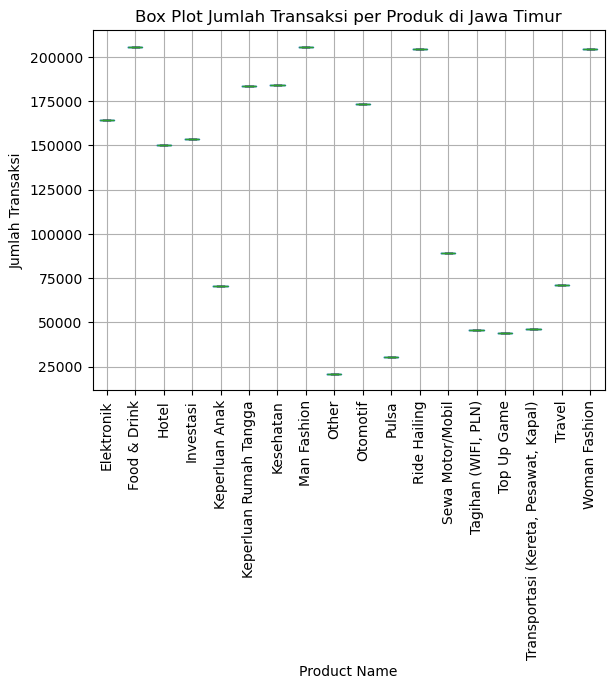

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Asumsikan 'main_trx' dan 'df_product' sudah ada dan memiliki data yang dibutuhkan

# Filter data transaksi untuk provinsi Jawa Timur
df_jatim = main_trx[main_trx['nama_provinsi'] == 'JAWA TIMUR']

# Menghitung jumlah transaksi per produk di Jawa Timur
transaksi_count_jatim = df_jatim['product_name'].value_counts().reset_index()
transaksi_count_jatim.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_jatim:", transaksi_count_jatim.columns)
print("Jumlah data di transaksi_count_jatim:", len(transaksi_count_jatim))

# Membuat box plot per kategori produk di Jawa Timur
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_jatim = transaksi_count_jatim.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_jatim.set_xlabel('Product Name')
boxplot_jatim.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Jawa Timur')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###2. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Sumatera Utara

Kolom di transaksi_count_sumut: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_sumut: 18


<Figure size 1200x800 with 0 Axes>

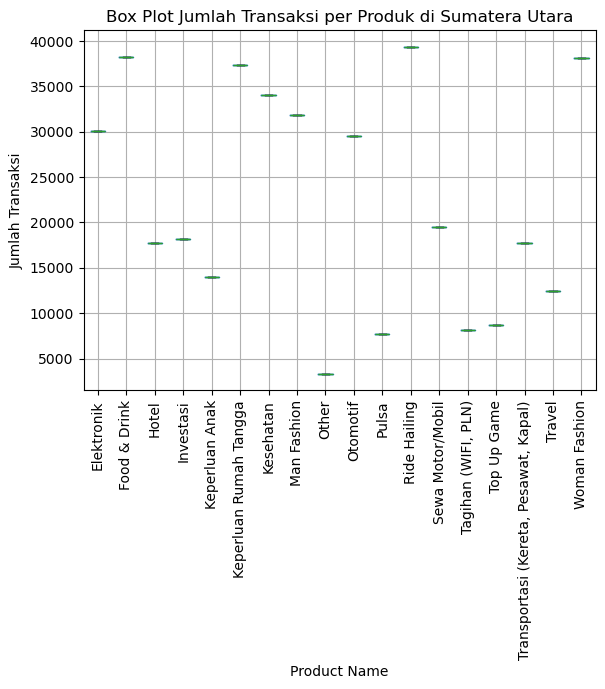

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi SUMATERA UTARA
df_sumut = main_trx[main_trx['nama_provinsi'] == 'SUMATERA UTARA']

# Menghitung jumlah transaksi per produk di Sumatera Utara
transaksi_count_sumut = df_sumut['product_name'].value_counts().reset_index()
transaksi_count_sumut.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_sumut:", transaksi_count_sumut.columns)
print("Jumlah data di transaksi_count_sumut:", len(transaksi_count_sumut))

# Membuat box plot per kategori produk di Sumatera Utara
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_sumut = transaksi_count_sumut.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_sumut.set_xlabel('Product Name')
boxplot_sumut.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Sumatera Utara')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###3. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Sumatera Barat

Kolom di transaksi_count_sumbar: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_sumbar: 18


<Figure size 1200x800 with 0 Axes>

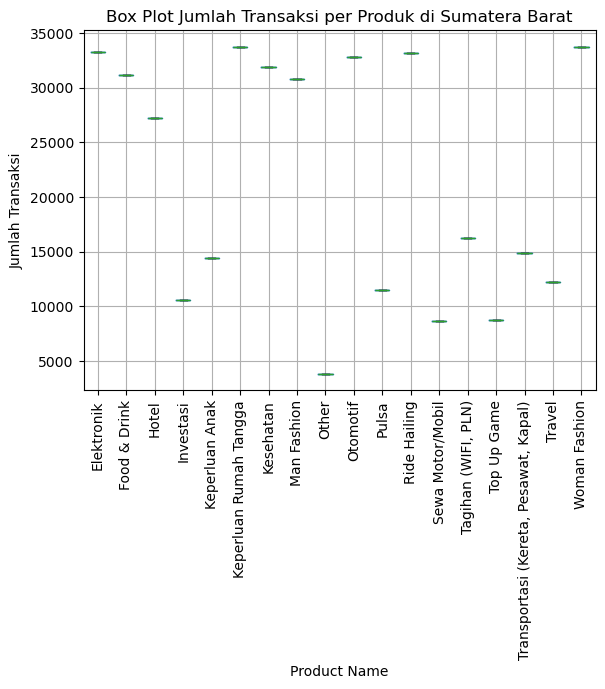

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi SUMATERA BARAT
df_sumbar = main_trx[main_trx['nama_provinsi'] == 'SUMATERA BARAT']

# Menghitung jumlah transaksi per produk di Sumatera Barat
transaksi_count_sumbar = df_sumbar['product_name'].value_counts().reset_index()
transaksi_count_sumbar.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_sumbar:", transaksi_count_sumbar.columns)
print("Jumlah data di transaksi_count_sumbar:", len(transaksi_count_sumbar))

# Membuat box plot per kategori produk di Sumatera Barat
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_sumbar = transaksi_count_sumbar.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_sumbar.set_xlabel('Product Name')
boxplot_sumbar.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Sumatera Barat')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###4. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Maluku

Kolom di transaksi_count_maluku: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_maluku: 18


<Figure size 1200x800 with 0 Axes>

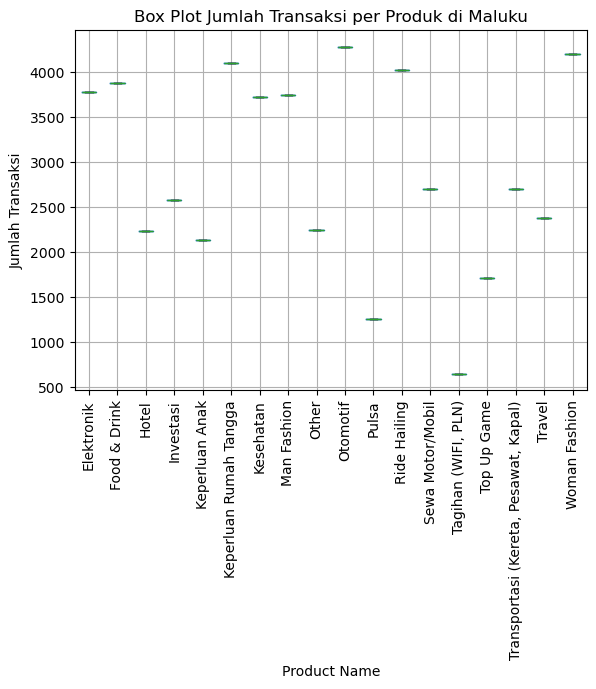

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi Maluku
df_maluku = main_trx[main_trx['nama_provinsi'] == 'MALUKU']

# Menghitung jumlah transaksi per produk di Maluku
transaksi_count_maluku = df_maluku['product_name'].value_counts().reset_index()
transaksi_count_maluku.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_maluku:", transaksi_count_maluku.columns)
print("Jumlah data di transaksi_count_maluku:", len(transaksi_count_maluku))

# Membuat box plot per kategori produk di Maluku
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_maluku = transaksi_count_maluku.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_maluku.set_xlabel('Product Name')
boxplot_maluku.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Maluku')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


### 5. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Jawa Timur

In [46]:
# Filter data transaksi untuk masing-masing kategori produk di Jawa Timur
fooddrink_jatim_data = main_trx[(main_trx['product_name'] == 'Food & Drink') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]
manfashion_jatim_data = main_trx[(main_trx['product_name'] == 'Man Fashion') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]
ridehailing_jatim_data = main_trx[(main_trx['product_name'] == 'Ride Hailing') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
fooddrink_jatim = fooddrink_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
manfashion_jatim = manfashion_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
ridehailing_jatim = ridehailing_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
fooddrink_jatim.rename(columns={'id': 'product_count'}, inplace=True)
manfashion_jatim.rename(columns={'id': 'product_count'}, inplace=True)
ridehailing_jatim.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("Data Food & Drink di Jawa Timur:")
print(fooddrink_jatim.head())

print("\nData Man Fashion di Jawa Timur:")
print(manfashion_jatim.head())

print("\nData Ride Hailing di Jawa Timur:")
print(ridehailing_jatim.head())

Data Food & Drink di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            588    58012500.0
1       2024-01-08           3842   328356000.0
2       2024-01-15           3925   343011100.0
3       2024-01-22           3827   320843400.0
4       2024-01-29           3801   315374400.0

Data Man Fashion di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            595    59314900.0
1       2024-01-08           3935   396008700.0
2       2024-01-15           3893   396357600.0
3       2024-01-22           3860   405731600.0
4       2024-01-29           3883   403515900.0

Data Ride Hailing di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            548    43260700.0
1       2024-01-08           3844   296794300.0
2       2024-01-15           3930   291115600.0
3       2024-01-22           3789   301118000.0
4       2024-01-29           3781   288735300.0


### 6. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Sumatera Utara

In [47]:
# Filter data transaksi untuk masing-masing kategori produk di Sumatera Utara
fooddrink_sumut_data = main_trx[(main_trx['product_name'] == 'Food & Drink') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]
ridehailing_sumut_data = main_trx[(main_trx['product_name'] == 'Ride Hailing') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]
womanfashion_sumut_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
fooddrink_sumut = fooddrink_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
ridehailing_sumut = ridehailing_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_sumut = womanfashion_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
fooddrink_sumut.rename(columns={'id': 'product_count'}, inplace=True)
ridehailing_sumut.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_sumut.rename(columns={'id': 'product_count'}, inplace=True)


# Verifikasi hasil
print("Data Food & Drink di Sumatera Utara:")
print(fooddrink_sumut.head())

print("\nData Ride Hailing di Sumatera Utara:")
print(ridehailing_sumut.head())

print("\nData Woman Fashion di Sumatera Utara:")
print(womanfashion_sumut.head())

Data Food & Drink di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01             90     7043900.0
1       2024-01-08            751    69789800.0
2       2024-01-15            755    61856400.0
3       2024-01-22            699    58548400.0
4       2024-01-29            728    70711800.0

Data Ride Hailing di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01             89    12739800.0
1       2024-01-08            729    93105300.0
2       2024-01-15            769    96927700.0
3       2024-01-22            728    94246500.0
4       2024-01-29            720    86874200.0

Data Woman Fashion di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01            109     6410900.0
1       2024-01-08            742    44907900.0
2       2024-01-15            708    42817400.0
3       2024-01-22            705    42068800.0
4       2024-01-29            688    40611600.0


### 7. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Sumatera Barat

In [48]:
# Filter data transaksi untuk masing-masing kategori produk di Sumatera Barat
elektronik_sumbar_data = main_trx[(main_trx['product_name'] == 'Elektronik') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]
keperluanRT_sumbar_data = main_trx[(main_trx['product_name'] == 'Keperluan Rumah Tangga') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]
womanfashion_sumbar_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
elektronik_sumbar = elektronik_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
keperluanRT_sumbar = keperluanRT_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_sumbar = womanfashion_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
elektronik_sumbar.rename(columns={'id': 'product_count'}, inplace=True)
keperluanRT_sumbar.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_sumbar.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("Data Elektronik di Sumatera Barat:")
print(elektronik_sumbar.head())

print("\nData Keperluan Rumah Tangga di Sumatera Barat:")
print(keperluanRT_sumbar.head())

print("\nData Woman Fashion di Sumatera Barat:")
print(womanfashion_sumbar.head())


Data Elektronik di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01            121     6060000.0
1       2024-01-08            610    37586500.0
2       2024-01-15            627    39190200.0
3       2024-01-22            594    37597600.0
4       2024-01-29            582    35698600.0

Data Keperluan Rumah Tangga di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01            101     7936800.0
1       2024-01-08            656    49373100.0
2       2024-01-15            593    48530800.0
3       2024-01-22            620    55572800.0
4       2024-01-29            613    49857100.0

Data Woman Fashion di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01             93     4775500.0
1       2024-01-08            589    40408100.0
2       2024-01-15            654    46899900.0
3       2024-01-22            630    43945200.0
4       2024-01-29            595    39120100.0


### 8. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Maluku

In [49]:
# Filter data transaksi untuk masing-masing kategori produk di Maluku
keperluanRT_maluku_data = main_trx[(main_trx['product_name'] == 'Keperluan Rumah Tangga') & (main_trx['nama_provinsi'] == 'MALUKU')]
otomotif_maluku_data = main_trx[(main_trx['product_name'] == 'Otomotif') & (main_trx['nama_provinsi'] == 'MALUKU')]
womanfashion_maluku_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'MALUKU')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
keperluanRT_maluku = keperluanRT_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
otomotif_maluku = otomotif_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_maluku = womanfashion_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
keperluanRT_maluku.rename(columns={'id': 'product_count'}, inplace=True)
otomotif_maluku.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_maluku.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("\nData Keperluan Rumah Tangga di Maluku:")
print(keperluanRT_maluku.head())

print("Data Otomotif di Maluku:")
print(otomotif_maluku.head())


print("\nData Woman Fashion di Maluku:")
print(womanfashion_maluku.head())



Data Keperluan Rumah Tangga di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             16     1279600.0
1       2024-01-08             54     3025300.0
2       2024-01-15             93     6269900.0
3       2024-01-22             74     5029600.0
4       2024-01-29             68     4590600.0
Data Otomotif di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             15     1888200.0
1       2024-01-08             83     7760300.0
2       2024-01-15             89     9618400.0
3       2024-01-22             75     5901400.0
4       2024-01-29             92    12281400.0

Data Woman Fashion di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             10     1134800.0
1       2024-01-08             81     5924200.0
2       2024-01-15             72     4787300.0
3       2024-01-22             78     5661400.0
4       2024-01-29             65     4279400.0


#**Time Series Forecasting Modeling**

#**Cek Decomposition Data**

In [50]:
# !pip install statsmodels
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

### 1. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Jawa Timur

Processing Food & Drink...


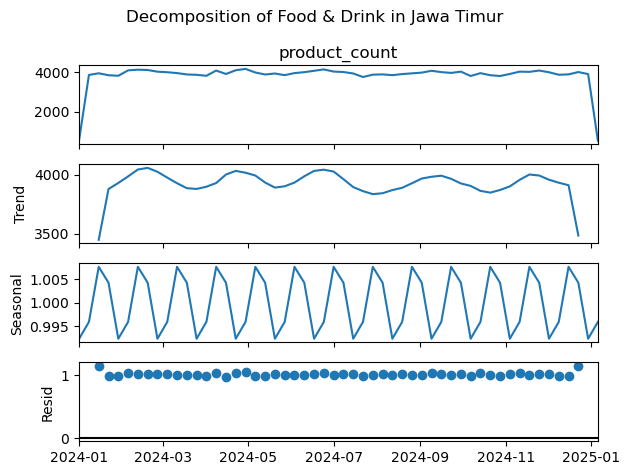

Processing Man Fashion...


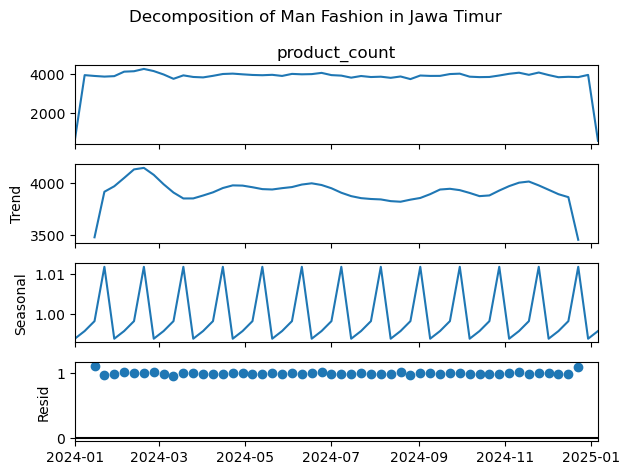

Processing Ride Hailing...


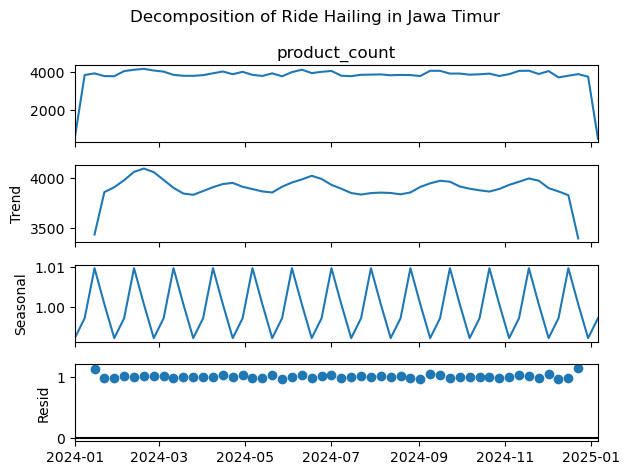

In [51]:
# Membuat dataset untuk masing-masing kategori produk
datasets_jatim = {
    'Food & Drink': fooddrink_jatim,
    'Man Fashion': manfashion_jatim,
    'Ride Hailing': ridehailing_jatim
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_jatim = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_jatim.resid

    # Plot the decomposition
    fig = decomposition_jatim.plot()
    fig.suptitle(f'Decomposition of {product} in Jawa Timur')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Food & Drink':
        decomposition_fooddrink_jatim = decomposition_jatim
    elif product == 'Man Fashion':
        decomposition_manfashion_jatim = decomposition_jatim
    elif product == 'Ride Hailing':
        decomposition_ridehailing_jatim = decomposition_jatim


### 2. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Utara

Processing Food & Drink...


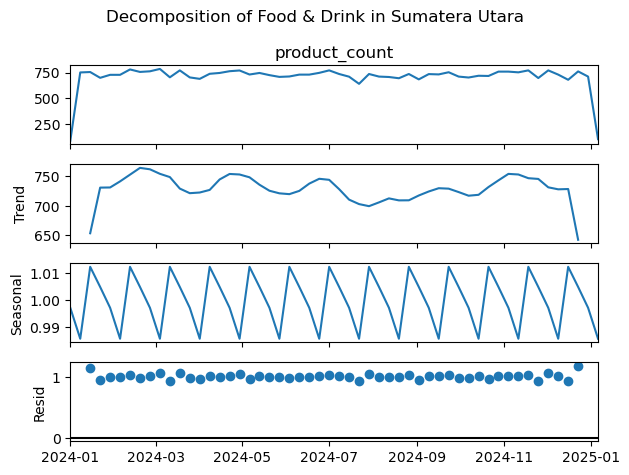

Processing Ride Hailing...


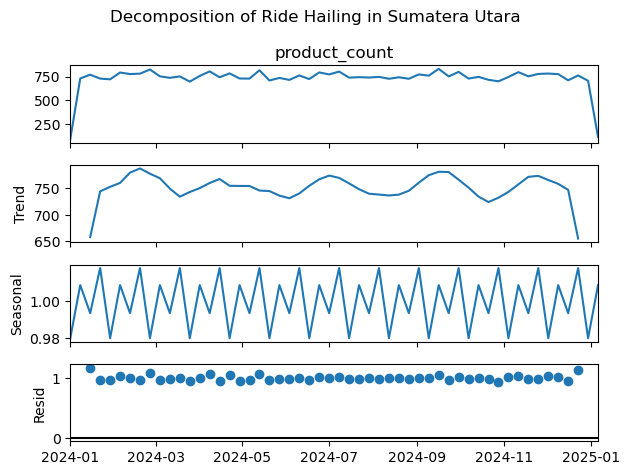

Processing Woman Fashion...


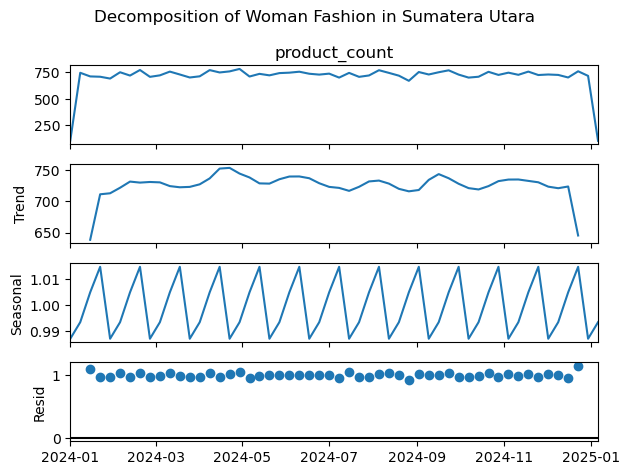

In [52]:
# Membuat dataset untuk masing-masing kategori produk
datasets_sumut = {
    'Food & Drink': fooddrink_sumut,
    'Ride Hailing': ridehailing_sumut,
    'Woman Fashion': womanfashion_sumut
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_sumut = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_sumut.resid

    # Plot the decomposition
    fig = decomposition_sumut.plot()
    fig.suptitle(f'Decomposition of {product} in Sumatera Utara')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Food & Drink':
        decomposition_fooddrink_sumut = decomposition_sumut
    elif product == 'Ride Hailing':
        decomposition_ridehailing_sumut = decomposition_sumut
    elif product == 'Woman Fashion':
        decomposition_womanfashion_sumut = decomposition_sumut


### 3. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Barat

Processing Elektronik...


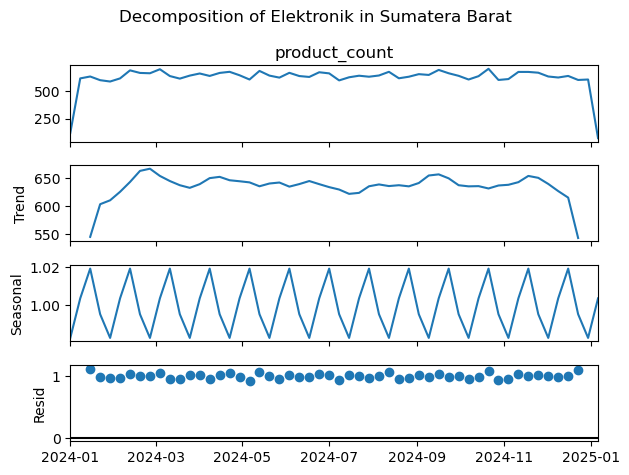

Processing Keperluan Rumah Tangga...


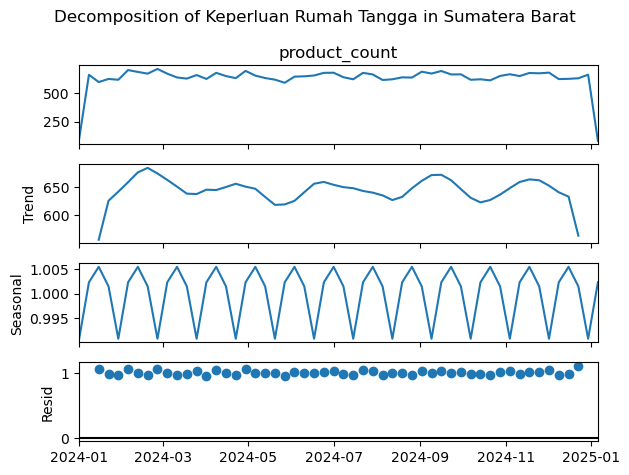

Processing Woman Fashion...


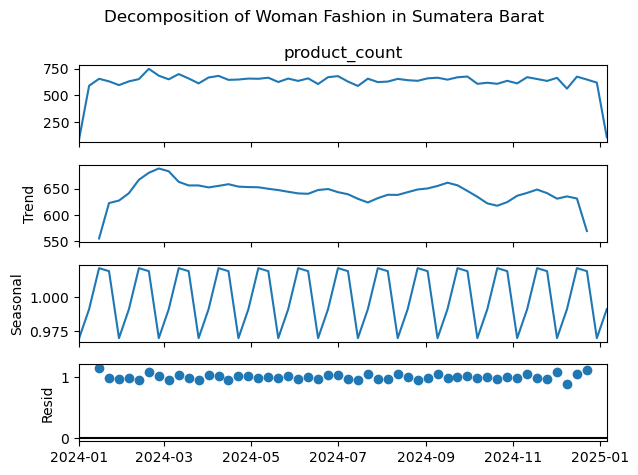

In [53]:
# Membuat dataset untuk masing-masing kategori produk
datasets_sumbar = {
    'Elektronik': elektronik_sumbar,
    'Keperluan Rumah Tangga': keperluanRT_sumbar,
    'Woman Fashion': womanfashion_sumbar
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_sumbar = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_sumbar.resid

    # Plot the decomposition
    fig = decomposition_sumbar.plot()
    fig.suptitle(f'Decomposition of {product} in Sumatera Barat')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Elektronik':
        decomposition_elektro_sumbar = decomposition_sumbar
    elif product == 'Keperluan Rumah Tangga':
        decomposition_krt_sumbar = decomposition_sumbar
    elif product == 'Woman Fashion':
        decomposition_wf_sumbar = decomposition_sumbar



### 4. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Maluku

Processing Keperluan Rumah Tangga...


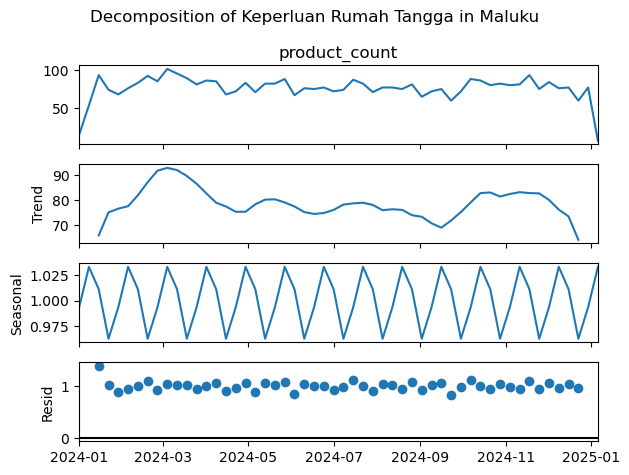

Processing Otomotif...


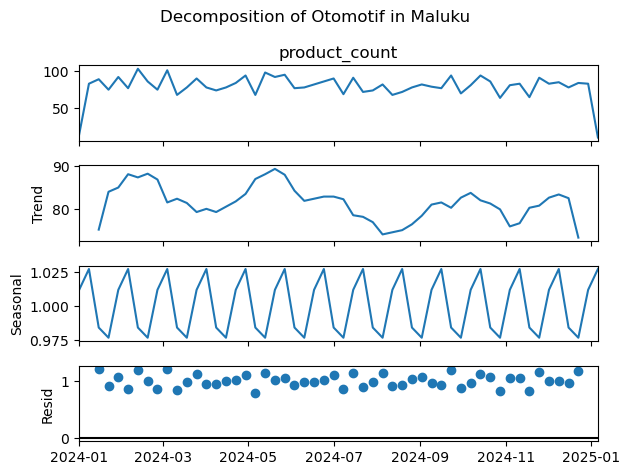

Processing Woman Fashion...


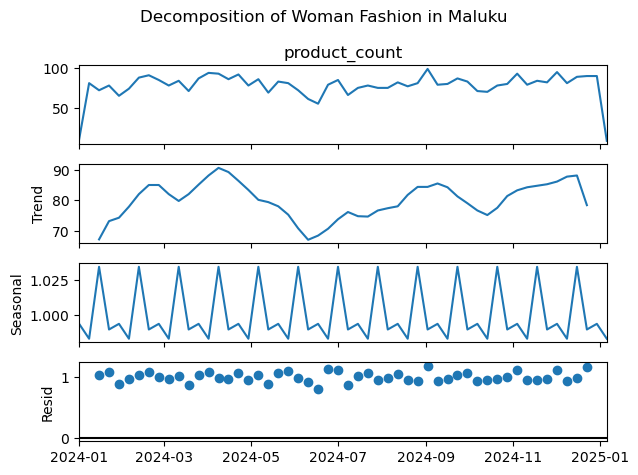

In [54]:
# Membuat dataset untuk masing-masing kategori produk
datasets_maluku = {
    'Keperluan Rumah Tangga': keperluanRT_maluku,
    'Otomotif': otomotif_maluku,
    'Woman Fashion': womanfashion_maluku
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_maluku = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_maluku.resid

    # Plot the decomposition
    fig = decomposition_maluku.plot()
    fig.suptitle(f'Decomposition of {product} in Maluku')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Keperluan Rumah Tangga':
        decomposition_krt_maluku = decomposition_maluku
    elif product == 'Otomotif':
        decomposition_otomotif_maluku = decomposition_maluku
    elif product == 'Woman Fashion':
        decomposition_wf_maluku = decomposition_maluku

#**Check Stationarity Data**

### 1. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Jawa Timur

In [55]:
# Loop through each dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada product_count
    if not data['residual'].isnull().values.any():  # Pastikan tidak ada NaN
        result = adfuller(data['residual'])
        print(f'ADF Statistic for {product}: {result[0]}')
        print(f'p-value for {product}: {result[1]}')
        print('Critical Values:')
        for key, value in result[4].items():
            print(f'\t{key}: {value:.3f}')

Processing Food & Drink...
ADF Statistic for Food & Drink: -7.094386118729598
p-value for Food & Drink: 4.327109174944142e-10
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Man Fashion...
ADF Statistic for Man Fashion: -5.847687412745691
p-value for Man Fashion: 3.650866252598523e-07
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Ride Hailing...
ADF Statistic for Ride Hailing: -4.005975162323056
p-value for Ride Hailing: 0.0013795447072493694
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602


In [56]:
# Loop through each dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Food & Drink...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                 3925   343011100.0  1.129955
2024-01-22                 3827   320843400.0  0.982786
2024-01-29                 3801   315374400.0  0.975042
2024-02-05                 4072   342055900.0  1.026258
2024-02-12                 4106   352057000.0  1.007876
Processing Man Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                 3893   396357600.0  1.119973
2024-01-22                 3860   405731600.0  0.974496
2024-01-29                 3883   403515900.0  0.984718
2024-02-05                 4112   430256100.0  1.020448
2024-02-12                 4134   432174900.0  1.003208
Processing Ride Hailing...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15              

### 2. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Utara

In [57]:
# Loop through each dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada product_count
    if not data['residual'].isnull().values.any():  # Pastikan tidak ada NaN
        result = adfuller(data['residual'])
        print(f'ADF Statistic for {product}: {result[0]}')
        print(f'p-value for {product}: {result[1]}')
        print('Critical Values:')
        for key, value in result[4].items():
            print(f'\t{key}: {value:.3f}')

Processing Food & Drink...
ADF Statistic for Food & Drink: -4.876078214195343
p-value for Food & Drink: 3.88127981416464e-05
Critical Values:
	1%: -3.585
	5%: -2.928
	10%: -2.602
Processing Ride Hailing...
ADF Statistic for Ride Hailing: -8.961744857117294
p-value for Ride Hailing: 8.189166844190881e-15
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -5.482289785160003
p-value for Woman Fashion: 2.27012709344012e-06
Critical Values:
	1%: -3.589
	5%: -2.930
	10%: -2.603


In [58]:
# Loop through each dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Food & Drink...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  755    61856400.0  1.141251
2024-01-22                  699    58548400.0  0.952407
2024-01-29                  728    70711800.0  0.999264
2024-02-05                  728    58779700.0  0.996911
2024-02-12                  780    74553300.0  1.024265
Processing Ride Hailing...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  769    96927700.0  1.177080
2024-01-22                  728    94246500.0  0.960695
2024-01-29                  720    86874200.0  0.975692
2024-02-05                  792    95731600.0  1.032427
2024-02-12                  776    97802400.0  1.001441
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15            

### 3. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Barat

In [59]:
# Loop through each dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada residual
    result = adfuller(data['residual'])
    print(f'ADF Statistic for {product}: {result[0]}')
    print(f'p-value for {product}: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')


Processing Elektronik...
ADF Statistic for Elektronik: -5.479909847252781
p-value for Elektronik: 2.2966935778330635e-06
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602
Processing Keperluan Rumah Tangga...
ADF Statistic for Keperluan Rumah Tangga: -8.973567041040187
p-value for Keperluan Rumah Tangga: 7.63807445359913e-15
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -10.055489342435155
p-value for Woman Fashion: 1.3766318774047426e-17
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600


In [60]:
# Loop through each dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Elektronik...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  627    39190200.0  1.127727
2024-01-22                  594    37597600.0  0.989569
2024-01-29                  582    35698600.0  0.970798
2024-02-05                  610    36154700.0  0.972527
2024-02-12                  682    38772100.0  1.041699
Processing Keperluan Rumah Tangga...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  593    48530800.0  1.059838
2024-01-22                  620    55572800.0  0.989561
2024-01-29                  613    49857100.0  0.964045
2024-02-05                  697    57523500.0  1.056053
2024-02-12                  681    54812400.0  1.001960
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15    

### 4. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Maluku

In [61]:
# Loop through each dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada residual
    result = adfuller(data['residual'])
    print(f'ADF Statistic for {product}: {result[0]}')
    print(f'p-value for {product}: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')


Processing Keperluan Rumah Tangga...
ADF Statistic for Keperluan Rumah Tangga: -8.171901876944911
p-value for Keperluan Rumah Tangga: 8.577938706493495e-13
Critical Values:
	1%: -3.578
	5%: -2.925
	10%: -2.601
Processing Otomotif...
ADF Statistic for Otomotif: -9.121489523637582
p-value for Otomotif: 3.1962905453690946e-15
Critical Values:
	1%: -3.578
	5%: -2.925
	10%: -2.601
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -5.896033067844456
p-value for Woman Fashion: 2.850062846869391e-07
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602


In [62]:
# Loop through each dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Keperluan Rumah Tangga...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                   93     6269900.0  1.399144
2024-01-22                   74     5029600.0  1.024667
2024-01-29                   68     4590600.0  0.894725
2024-02-05                   76     3818400.0  0.949621
2024-02-12                   83     3860600.0  1.002772
Processing Otomotif...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                   89     9618400.0  1.203871
2024-01-22                   75     5901400.0  0.914302
2024-01-29                   92    12281400.0  1.069538
2024-02-05                   77     6049700.0  0.850452
2024-02-12                  103     9412000.0  1.197911
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15      

#**Using Auto_Arima to chosse model and parameter**

In [63]:
# !pip install pmdarima
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from pmdarima import auto_arima
import matplotlib.pyplot as plt

### 1. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Jawa Timur

In [64]:
import pmdarima as pm

# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Food & Drink'
    if product == 'Food & Drink':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Food & Drink...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[4] intercept   : AIC=-178.012, Time=0.47 sec
 ARIMA(0,0,0)(0,1,0)[4] intercept   : AIC=-172.417, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[4] intercept   : AIC=-174.740, Time=0.17 sec
 ARIMA(0,0,1)(0,1,1)[4] intercept   : AIC=-180.013, Time=0.17 sec
 ARIMA(0,0,0)(0,1,0)[4]             : AIC=-174.417, Time=0.02 sec
 ARIMA(0,0,1)(0,1,0)[4] intercept   : AIC=-178.206, Time=0.15 sec
 ARIMA(0,0,1)(1,1,1)[4] intercept   : AIC=-178.021, Time=0.27 sec
 ARIMA(0,0,1)(0,1,2)[4] intercept   : AIC=-173.197, Time=0.18 sec
 ARIMA(0,0,1)(1,1,0)[4] intercept   : AIC=-178.769, Time=0.20 sec
 ARIMA(0,0,1)(1,1,2)[4] intercept   : AIC=inf, Time=0.46 sec
 ARIMA(0,0,0)(0,1,1)[4] intercept   : AIC=-175.050, Time=0.15 sec
 ARIMA(1,0,1)(0,1,1)[4] intercept   : AIC=-177.835, Time=0.12 sec
 ARIMA(0,0,2)(0,1,1)[4] intercept   : AIC=-177.933, Time=0.18 sec
 ARIMA(1,0,0)(0,1,1)[4] intercept   : AIC=-175.818, Time=0.15 sec
 ARIMA(1,0,

In [65]:
# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Man Fashion'
    if product == 'Man Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Man Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-221.402, Time=0.44 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-223.061, Time=0.04 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.23 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-226.740, Time=0.13 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.335, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[4] intercept   : AIC=-228.393, Time=0.05 sec
 ARIMA(0,0,1)(1,0,0)[4] intercept   : AIC=-189.412, Time=0.25 sec
 ARIMA(0,0,1)(1,0,1)[4] intercept   : AIC=-224.134, Time=0.37 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=-219.321, Time=0.16 sec
 ARIMA(0,0,2)(0,0,0)[4] intercept   : AIC=-226.558, Time=0.18 sec
 ARIMA(1,0,0)(0,0,0)[4] intercept   : AIC=-224.051, Time=0.11 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-225.235, Time=0.46 sec
 ARIMA(0,0,1)(0,0,0)[4]             : AIC=inf, Time=0.05 sec

Best model:  ARIMA(0,0,1)(0,0,0)[4] intercept
Total fit time: 2.530 seconds
       

In [66]:
# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Ride Hailing'
    if product == 'Ride Hailing':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Ride Hailing...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-209.004, Time=0.65 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-193.524, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.12 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-208.956, Time=0.12 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.453, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-210.281, Time=0.15 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-211.599, Time=0.09 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-144.589, Time=0.22 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=inf, Time=0.15 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-213.276, Time=0.14 sec
 ARIMA(2,0,1)(1,0,0)[4] intercept   : AIC=-165.184, Time=0.23 sec
 ARIMA(2,0,1)(0,0,1)[4] intercept   : AIC=-208.265, Time=0.41 sec
 ARIMA(2,0,1)(1,0,1)[4] intercept   : AIC=-205.856, Time=0.09 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=-196.740, Time=0.13 sec
 ARIMA(2,0,0)(0,0

### 2. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Sumatera Utara

In [67]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Food & Drink'
    if product == 'Food & Drink':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Food & Drink...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-187.481, Time=0.37 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-164.990, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=-184.330, Time=0.17 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.11 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.485, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-192.625, Time=0.22 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-185.149, Time=0.17 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=-183.934, Time=0.30 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-189.732, Time=0.25 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=-113.045, Time=0.33 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=inf, Time=0.15 sec
 ARIMA(2,0,1)(0,0,1)[4] intercept   : AIC=-197.690, Time=0.32 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-186.868, Time=0.06 sec
 ARIMA(2,0,1)(1,0,1)[4] intercept   : AIC=-194.028, Time=0.44 sec
 ARIMA(2,0,1)(0,0

In [68]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Ride Hailing'
    if product == 'Ride Hailing':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Ride Hailing...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-174.880, Time=0.20 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-164.391, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.16 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.13 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.548, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-177.557, Time=0.17 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-178.438, Time=0.14 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-125.577, Time=0.25 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-179.397, Time=0.16 sec
 ARIMA(1,0,2)(1,0,0)[4] intercept   : AIC=inf, Time=0.39 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=-181.773, Time=0.15 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=-176.242, Time=0.16 sec
 ARIMA(1,0,2)(0,0,2)[4] intercept   : AIC=-179.625, Time=0.17 sec
 ARIMA(1,0,2)(1,0,2)[4] intercept   : AIC=-174.803, Time=0.93 sec
 ARIMA(0,0,2)(0,0,1)[4

In [69]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-189.302, Time=0.31 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-182.568, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.13 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.16 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.399, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=inf, Time=0.65 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-146.369, Time=0.25 sec
 ARIMA(2,0,2)(2,0,1)[4] intercept   : AIC=inf, Time=0.46 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=inf, Time=0.37 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=inf, Time=0.29 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=0.89 sec
 ARIMA(2,0,2)(2,0,0)[4] intercept   : AIC=inf, Time=0.37 sec
 ARIMA(2,0,2)(2,0,2)[4] intercept   : AIC=-53.532, Time=0.38 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=-195.077, Time=0.38 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=-187.

### 3. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Sumatera Barat

In [70]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Elektronik'
    if product == 'Elektronik':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Elektronik...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-183.556, Time=0.45 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-171.206, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.17 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.12 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.435, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-196.231, Time=0.21 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-193.504, Time=0.20 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=-197.538, Time=0.58 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=-157.237, Time=0.49 sec
 ARIMA(1,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=0.57 sec
 ARIMA(2,0,1)(0,0,2)[4] intercept   : AIC=inf, Time=0.20 sec
 ARIMA(3,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=0.42 sec
 ARIMA(2,0,3)(0,0,2)[4] intercept   : AIC=-192.871, Time=0.37 sec
 ARIMA(1,0,1)(0,0,2)[4] intercept   : AIC=inf, Time=0.35 sec
 ARIMA(1,0,3)(0,0,2)[4] intercept   : A

In [71]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Keperluan Rumah Tangga'
    if product == 'Keperluan Rumah Tangga':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Keperluan Rumah Tangga...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-204.166, Time=0.31 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-194.444, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.14 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-208.809, Time=0.05 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.262, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[4] intercept   : AIC=inf, Time=0.07 sec
 ARIMA(0,0,1)(1,0,1)[4] intercept   : AIC=-205.882, Time=0.72 sec
 ARIMA(0,0,1)(0,0,2)[4] intercept   : AIC=-207.221, Time=0.11 sec
 ARIMA(0,0,1)(1,0,0)[4] intercept   : AIC=-153.173, Time=0.36 sec
 ARIMA(0,0,1)(1,0,2)[4] intercept   : AIC=-199.079, Time=0.50 sec
 ARIMA(0,0,0)(0,0,1)[4] intercept   : AIC=-192.723, Time=0.03 sec
 ARIMA(1,0,1)(0,0,1)[4] intercept   : AIC=-188.723, Time=0.13 sec
 ARIMA(0,0,2)(0,0,1)[4] intercept   : AIC=-208.635, Time=0.13 sec
 ARIMA(1,0,0)(0,0,1)[4] intercept   : AIC=-196.186, Time=0.05 sec
 ARIMA(

In [72]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-181.856, Time=0.49 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-163.544, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.16 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.11 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.528, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-186.663, Time=0.21 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-190.079, Time=0.21 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-105.971, Time=0.25 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-185.816, Time=0.32 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-183.654, Time=0.12 sec
 ARIMA(3,0,2)(0,0,0)[4] intercept   : AIC=-180.211, Time=0.20 sec
 ARIMA(2,0,3)(0,0,0)[4] intercept   : AIC=-186.519, Time=0.19 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=-161.485, Time=0.15 sec
 ARIMA(1,0,3)(0,0,0)[4] intercept   : AIC=-186.682, Time=0.10 sec
 ARIMA(3,0,1)(0,

### 4. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Maluku

In [73]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Keperluan Rumah Tangga'
    if product == 'Keperluan Rumah Tangga':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Keperluan Rumah Tangga...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=inf, Time=0.40 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-98.183, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=-85.226, Time=0.13 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=145.001, Time=0.01 sec
 ARIMA(0,0,0)(1,0,0)[4] intercept   : AIC=-93.733, Time=0.11 sec
 ARIMA(0,0,0)(0,0,1)[4] intercept   : AIC=-96.412, Time=0.05 sec
 ARIMA(0,0,0)(1,0,1)[4] intercept   : AIC=inf, Time=0.15 sec
 ARIMA(1,0,0)(0,0,0)[4] intercept   : AIC=-99.728, Time=0.04 sec
 ARIMA(1,0,0)(0,0,1)[4] intercept   : AIC=-98.393, Time=0.08 sec
 ARIMA(1,0,0)(1,0,1)[4] intercept   : AIC=inf, Time=0.25 sec
 ARIMA(2,0,0)(0,0,0)[4] intercept   : AIC=-109.097, Time=0.13 sec
 ARIMA(2,0,0)(1,0,0)[4] intercept   : AIC=-88.360, Time=0.17 sec
 ARIMA(2,0,0)(0,0,1)[4] intercept   : AIC=-107.134, Time=0.12 sec
 ARIMA(2,0,0)(1,0,1)[4] 

In [74]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Otomotif'
    if product == 'Otomotif':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Otomotif...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[4] intercept   : AIC=inf, Time=0.23 sec
 ARIMA(0,0,0)(0,1,0)[4] intercept   : AIC=-34.365, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[4] intercept   : AIC=-56.231, Time=0.05 sec
 ARIMA(0,0,1)(0,1,1)[4] intercept   : AIC=inf, Time=0.12 sec
 ARIMA(0,0,0)(0,1,0)[4]             : AIC=-36.359, Time=0.01 sec
 ARIMA(1,0,0)(0,1,0)[4] intercept   : AIC=-53.942, Time=0.05 sec
 ARIMA(1,0,0)(2,1,0)[4] intercept   : AIC=-59.356, Time=0.09 sec
 ARIMA(1,0,0)(2,1,1)[4] intercept   : AIC=inf, Time=0.24 sec
 ARIMA(1,0,0)(1,1,1)[4] intercept   : AIC=inf, Time=0.17 sec
 ARIMA(0,0,0)(2,1,0)[4] intercept   : AIC=-42.451, Time=0.05 sec
 ARIMA(2,0,0)(2,1,0)[4] intercept   : AIC=-79.126, Time=0.15 sec
 ARIMA(2,0,0)(1,1,0)[4] intercept   : AIC=-76.537, Time=0.08 sec
 ARIMA(2,0,0)(2,1,1)[4] intercept   : AIC=-84.532, Time=0.20 sec
 ARIMA(2,0,0)(1,1,1)[4] intercept   : AIC=inf, Time=0.19 sec
 ARIMA(2,0,0)(2,1,2)[4] intercept   : AIC=-8

In [75]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-121.582, Time=0.32 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-106.982, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.11 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.501, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-127.333, Time=0.25 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-130.180, Time=0.28 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=inf, Time=0.24 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=inf, Time=0.12 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-108.910, Time=0.08 sec
 ARIMA(3,0,2)(0,0,0)[4] intercept   : AIC=-122.046, Time=0.19 sec
 ARIMA(2,0,3)(0,0,0)[4] intercept   : AIC=-127.178, Time=0.11 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=inf, Time=0.11 sec
 ARIMA(1,0,3)(0,0,0)[4] intercept   : AIC=-129.383, Time=0.09 sec
 ARIMA(3,0,1)(0,0,0)[4] interce

# **Modeling Dataset for TimeSeries**

###1. Modeling 3 dataset berdasarkan produk dalam Jawa Timur

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


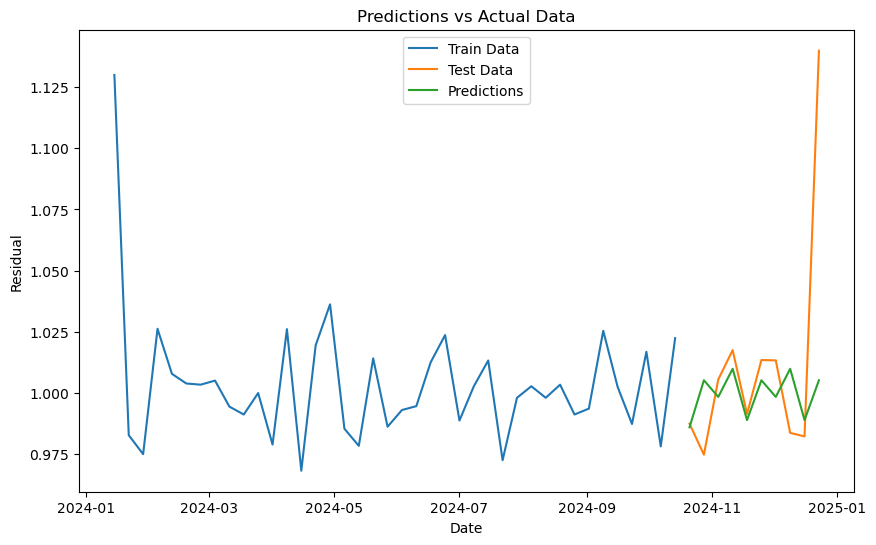

Root Mean Squared Error: 0.044924203250557015


In [76]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Food & Drink'
data_fooddrink = datasets_jatim['Food & Drink']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_fooddrink['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


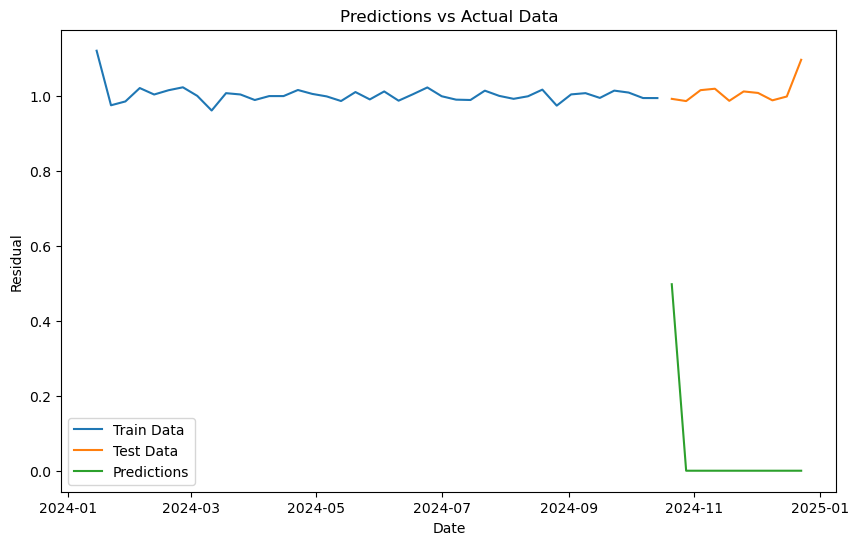

Root Mean Squared Error: 0.9729365233061947


In [77]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Man Fashion'
data_manfashion = datasets_jatim['Man Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_manfashion['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 0, 0)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_mf = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_mf.index, predictions_mf, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_mf)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


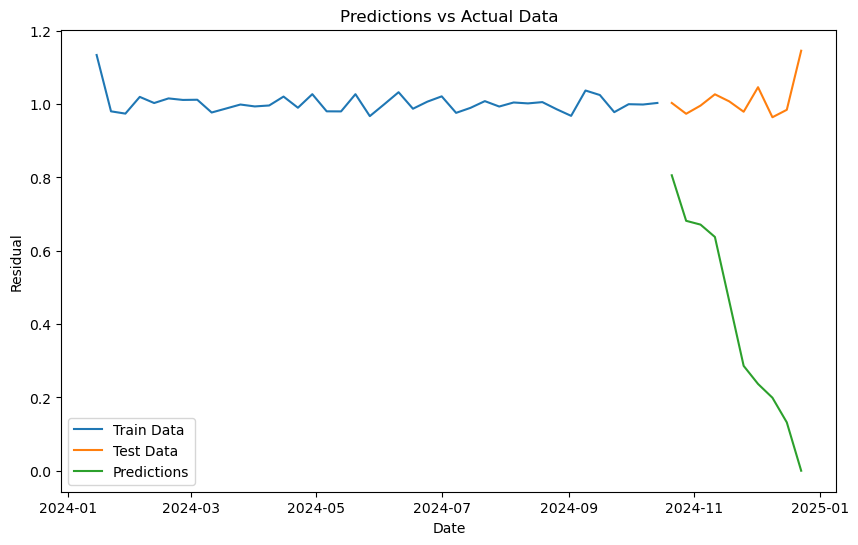

Root Mean Squared Error: 0.6663191495782012


In [78]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Ride Hailing'
data_ridehailing = datasets_jatim['Ride Hailing']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_ridehailing['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, [1,2], 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_rh = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_rh.index, predictions_rh, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_rh)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###2. Modeling 3 dataset berdasarkan produk dalam Sumatera Utara

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


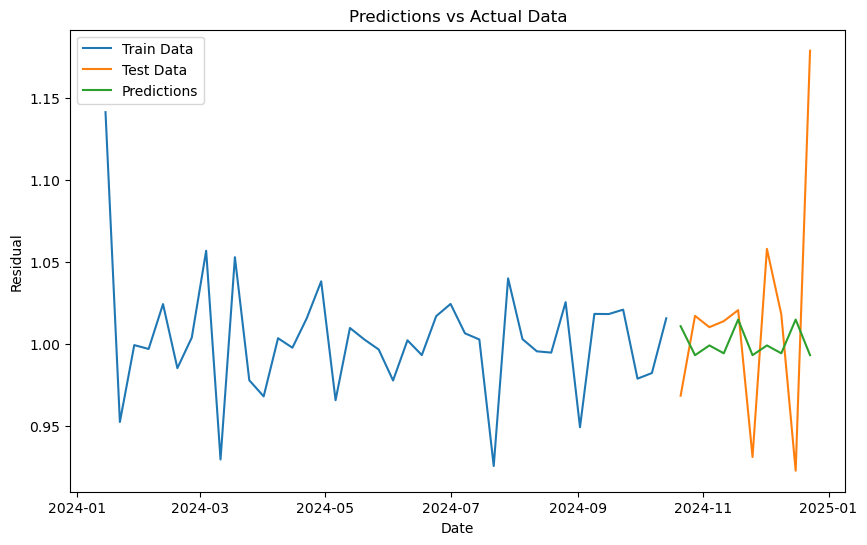

Root Mean Squared Error: 0.07330001400660699


In [79]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Food & Drink'
data_fooddrink = datasets_sumut['Food & Drink']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_fooddrink['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


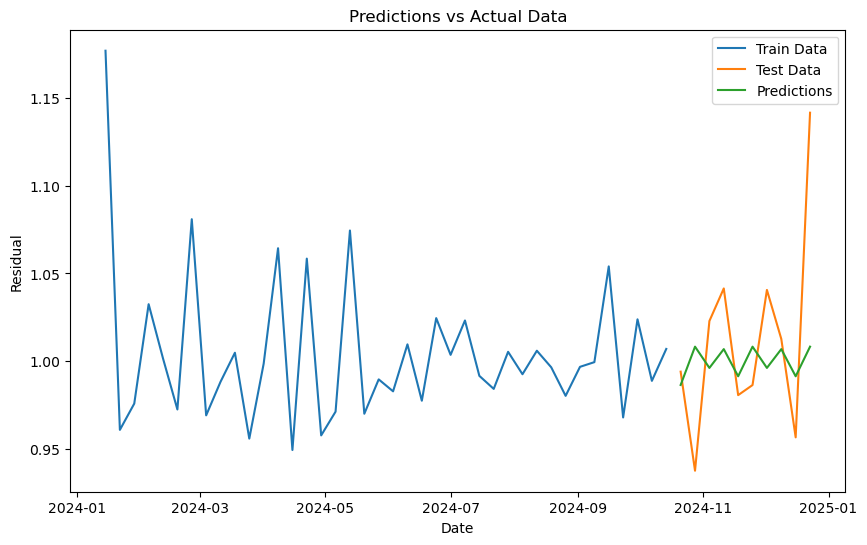

Root Mean Squared Error: 0.05351613713435925


In [80]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Ride Hailing'
data_ridehailing = datasets_sumut['Ride Hailing']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_ridehailing['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


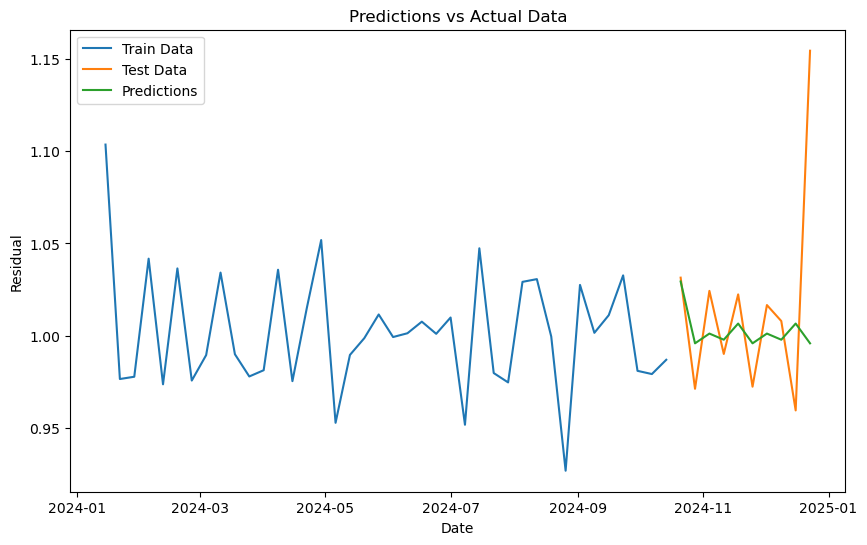

Root Mean Squared Error: 0.05452033316379637


In [81]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Woman Fashion'
data_womanfashion = datasets_sumut['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_womanfashion['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###3. Modeling 3 dataset berdasarkan produk dalam Sumatera Barat

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\statespa

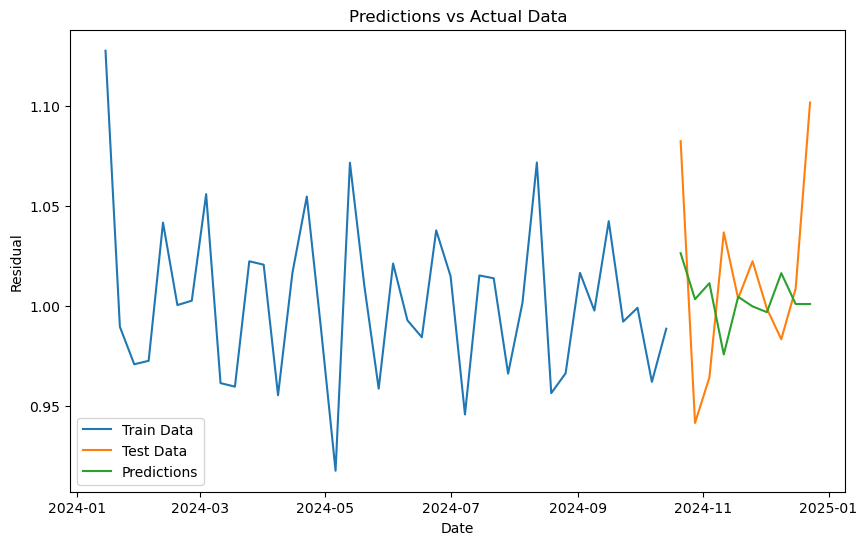

Root Mean Squared Error: 0.04977853860455806


In [82]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_elektro = datasets_sumbar['Elektronik']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_elektro['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (2, 0, 2)  # Orde ARIMA
seasonal_order = (0, 0, 2, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_e = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_e.index, predictions_e, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_e)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


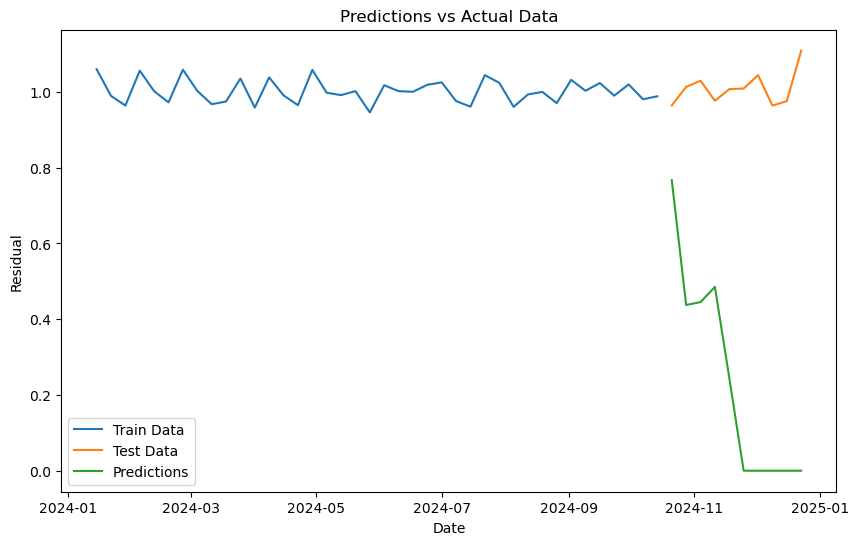

Root Mean Squared Error: 0.8218304782127989


In [83]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_krt = datasets_sumbar['Keperluan Rumah Tangga']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


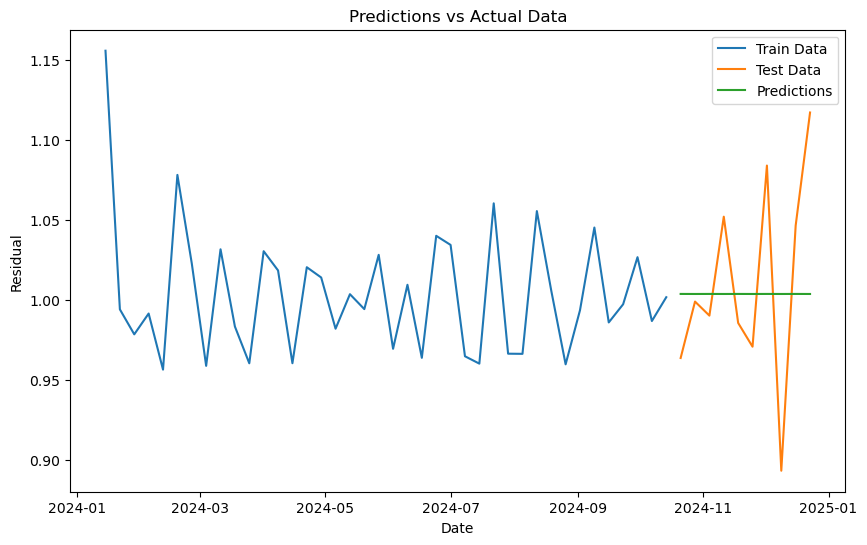

Root Mean Squared Error: 0.062412203861569725


In [84]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_wf = datasets_sumbar['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_wf['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (2, 0, 2)  # Orde ARIMA
seasonal_order = (0, 0, 0, 0)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_wf = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_wf.index, predictions_wf, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_wf)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###4. Modeling 3 dataset berdasarkan produk dalam Maluku

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


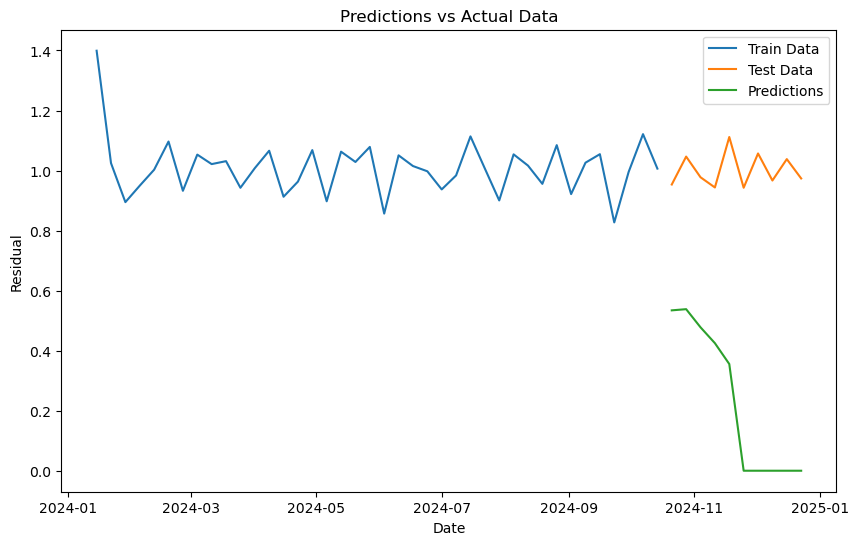

Root Mean Squared Error: 0.8056513939832082


In [85]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
data_krt = datasets_maluku['Keperluan Rumah Tangga']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()

# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


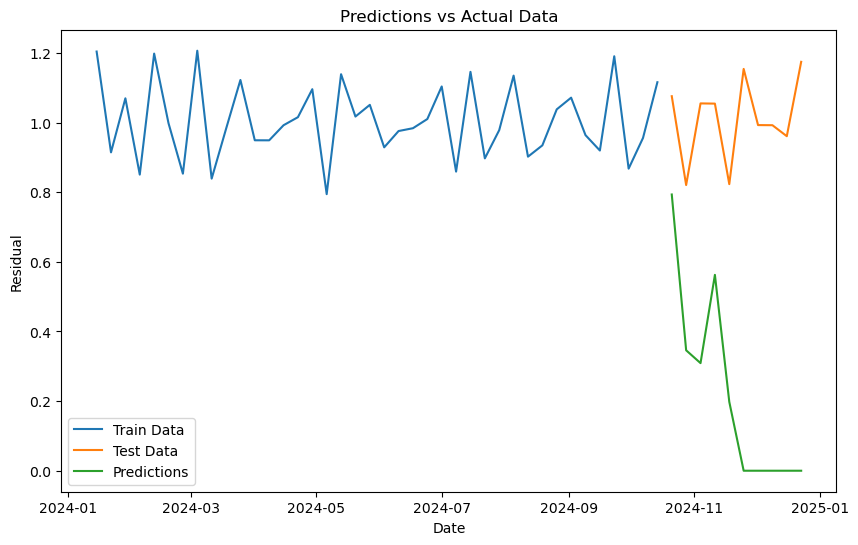

Root Mean Squared Error: 0.8424880487989287


In [86]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Otomotif'
data_krt = datasets_maluku['Otomotif']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Rebecca YBS\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


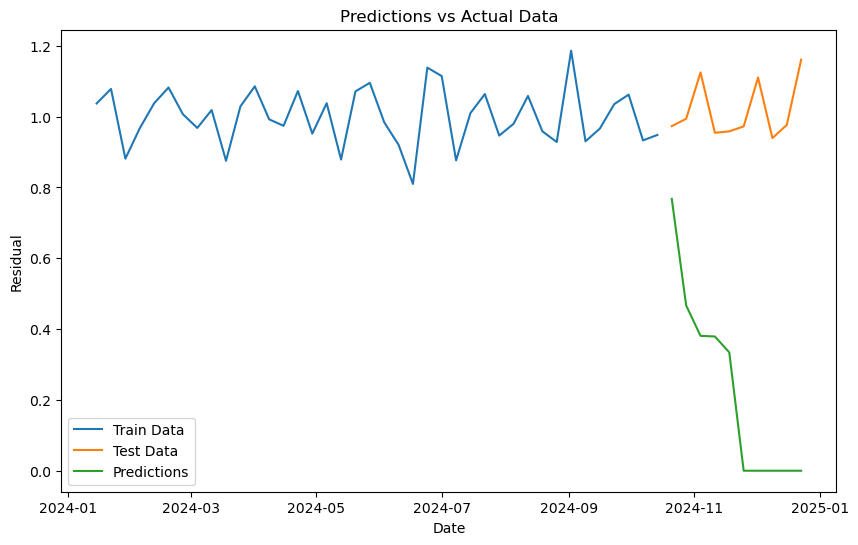

Root Mean Squared Error: 0.833885187350192


In [87]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Woman Fashion'
data_krt = datasets_maluku['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

#**Undo Stationarity To Testing Dataset**

### 1. Undo Stationarity 3 Dataset berdasarkan produk dalam Jawa Timur

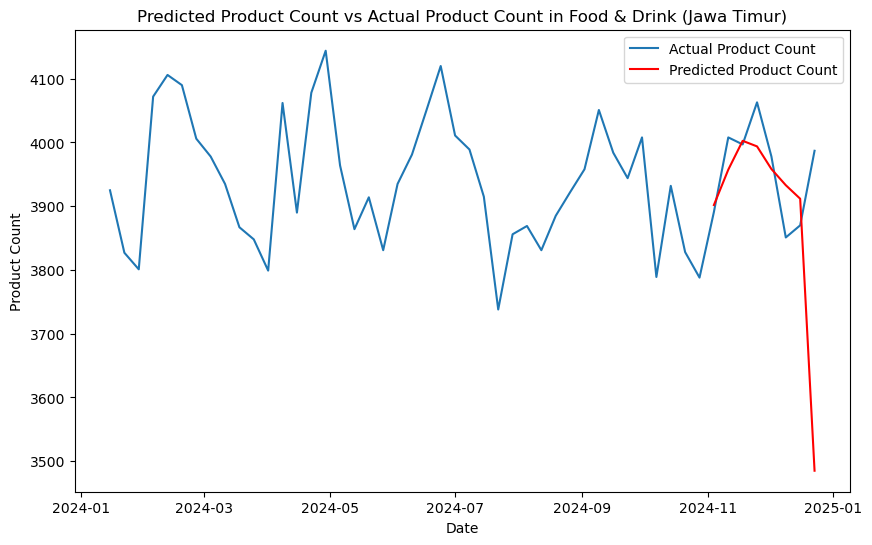

Root Mean Squared Error: 183.14890714382233


In [88]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Food & Drink'
if decomposition_fooddrink_jatim is not None:
    # Ambil dataset untuk kategori 'Food & Drink'
    data_fooddrink = datasets_jatim['Food & Drink']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_fooddrink_jatim.trend[-len(predictions_fd):]
    seasonal_component = decomposition_fooddrink_jatim.seasonal[-len(predictions_fd):]
    predictions_product_count = trend_component + seasonal_component + predictions_fd

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_fooddrink['product_count'].index, data_fooddrink['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Food & Drink (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")

In [89]:
import pandas as pd

if decomposition_fooddrink_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_fd_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_fd_pred.head())

else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3901.868380
1 2024-11-11                  4008                3957.368678
2 2024-11-18                  3997                4002.639275
3 2024-11-25                  4063                3993.875140
4 2024-12-02                  3978                3958.368380


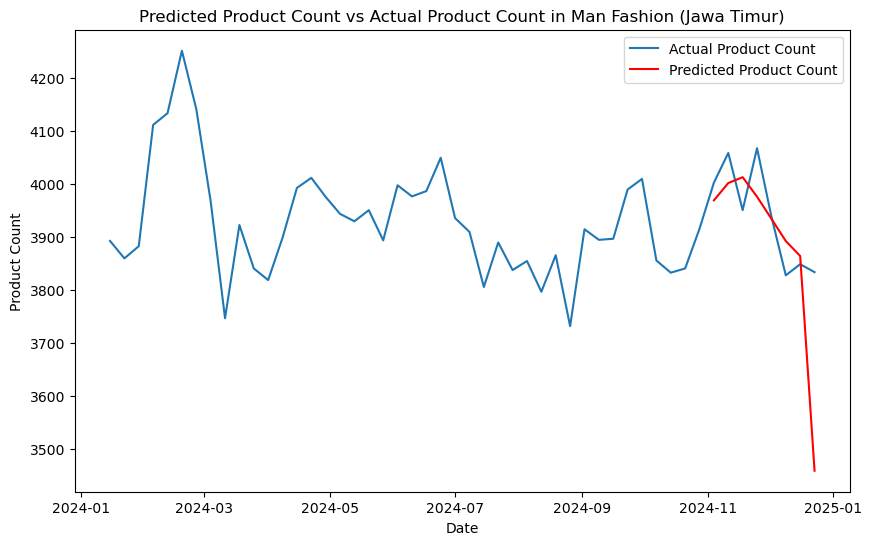

Root Mean Squared Error: 192.43307721708416


In [90]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Man Fashion'
if decomposition_manfashion_jatim is not None:
    # Ambil dataset untuk kategori 'Man Faashion'
    data_manfashion = datasets_jatim['Man Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_manfashion_jatim.trend[-len(predictions_mf):]
    seasonal_component = decomposition_manfashion_jatim.seasonal[-len(predictions_mf):]
    predictions_product_count = trend_component + seasonal_component + predictions_mf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_manfashion['product_count'].index, data_manfashion['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Man Fashion (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Man Fashion' dataset.")

In [91]:
import pandas as pd

if decomposition_manfashion_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_mf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_mf_pred.head())

else:
    print("Warning: No decomposition results found for 'Man Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3969.493985
1 2024-11-11                  4008                4002.245886
2 2024-11-18                  3997                4013.248341
3 2024-11-25                  4063                3976.386788
4 2024-12-02                  3978                3934.743985


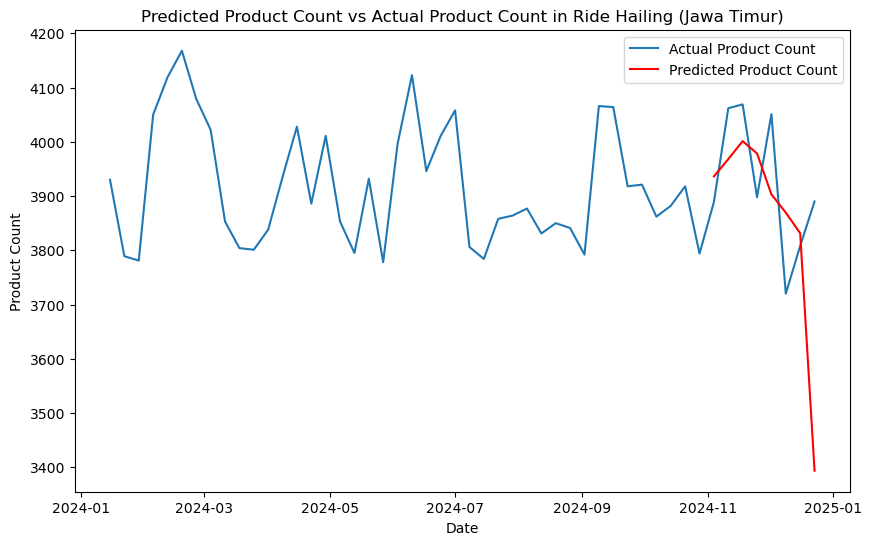

Root Mean Squared Error: 215.19298732409786


In [92]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Ride Hailing'
if decomposition_ridehailing_jatim is not None:
    # Ambil dataset untuk kategori 'Ride Hailing'
    data_ridehailing = datasets_jatim['Ride Hailing']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_ridehailing_jatim.trend[-len(predictions_rh):]
    seasonal_component = decomposition_ridehailing_jatim.seasonal[-len(predictions_rh):]
    predictions_product_count = trend_component + seasonal_component + predictions_rh

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_ridehailing['product_count'].index, data_ridehailing['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Ride Hailing (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


In [93]:
import pandas as pd

if decomposition_ridehailing_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_rh_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_rh_pred.head())

else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3936.288728
1 2024-11-11                  4008                3968.134964
2 2024-11-18                  3997                4001.222031
3 2024-11-25                  4063                3978.536762
4 2024-12-02                  3978                3903.104027


### 2. Undo Stationarity 3 Dataset berdasarkan produk dalam Sumatera Utara

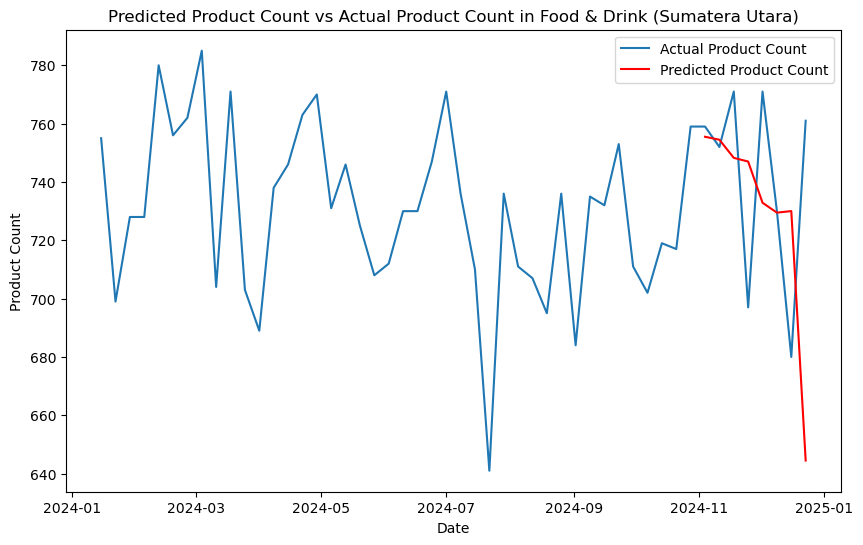

Root Mean Squared Error: 50.69897286503239


In [94]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Food & Drink'
if decomposition_fooddrink_sumut is not None:
    # Ambil dataset untuk kategori 'Food & Drink'
    data_fooddrink = datasets_sumut['Food & Drink']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_fooddrink_sumut.trend[-len(predictions_fd):]
    seasonal_component = decomposition_fooddrink_sumut.seasonal[-len(predictions_fd):]
    predictions_product_count = trend_component + seasonal_component + predictions_fd

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_fooddrink['product_count'].index, data_fooddrink['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Food & Drink (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")

In [95]:
import pandas as pd

if decomposition_fooddrink_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_fd_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_fd_pred.head())

else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   759                 755.498305
1 2024-11-11                   752                 754.483501
2 2024-11-18                   771                 748.268923
3 2024-11-25                   697                 747.000745
4 2024-12-02                   771                 732.873305


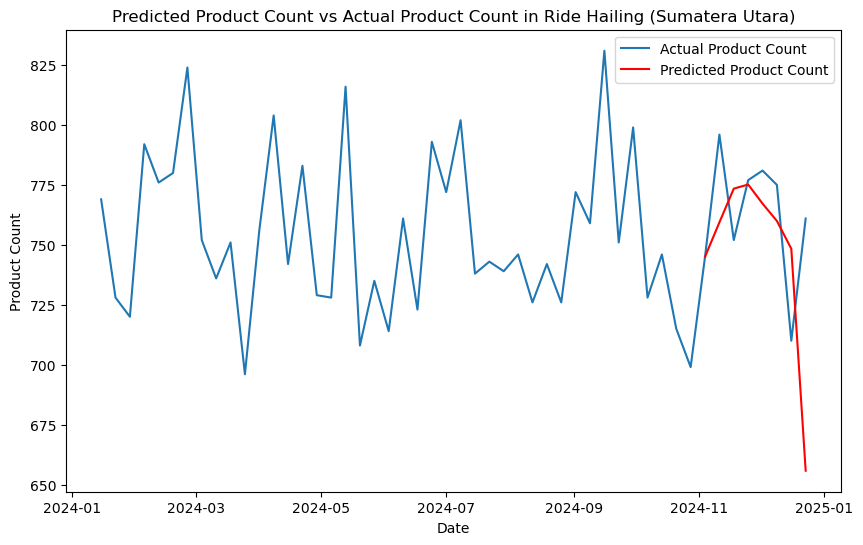

Root Mean Squared Error: 42.96244337132831


In [96]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Ride Hailing'
if decomposition_ridehailing_sumut is not None:
    # Ambil dataset untuk kategori 'Ride Hailing'
    data_ridehailing = datasets_sumut['Ride Hailing']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_ridehailing_sumut.trend[-len(predictions_rh):]
    seasonal_component = decomposition_ridehailing_sumut.seasonal[-len(predictions_rh):]
    predictions_product_count = trend_component + seasonal_component + predictions_rh

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_ridehailing['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_ridehailing['product_count'].index, data_ridehailing['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Ride Hailing (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


In [97]:
import pandas as pd

if decomposition_ridehailing_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_rh_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_rh_pred.head())

else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   745                 745.026265
1 2024-11-11                   796                 759.396429
2 2024-11-18                   752                 773.455754
3 2024-11-25                   777                 775.179036
4 2024-12-02                   781                 767.216565


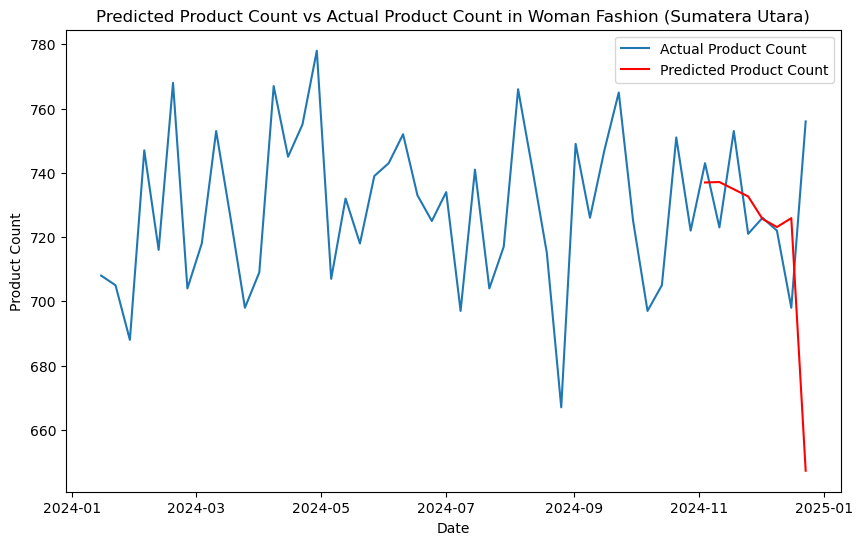

Root Mean Squared Error: 40.77487296026641


In [98]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_womanfashion_sumut is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_sumut['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_womanfashion_sumut.trend[-len(predictions_wf):]
    seasonal_component = decomposition_womanfashion_sumut.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_womanfashion['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [99]:
import pandas as pd

if decomposition_womanfashion_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   743                 736.990790
1 2024-11-11                   723                 737.122199
2 2024-11-18                   753                 734.883851
3 2024-11-25                   721                 732.643738
4 2024-12-02                   726                 725.615790


### 3. Undo Stationarity 3 Dataset berdasarkan produk dalam Sumatera Barat

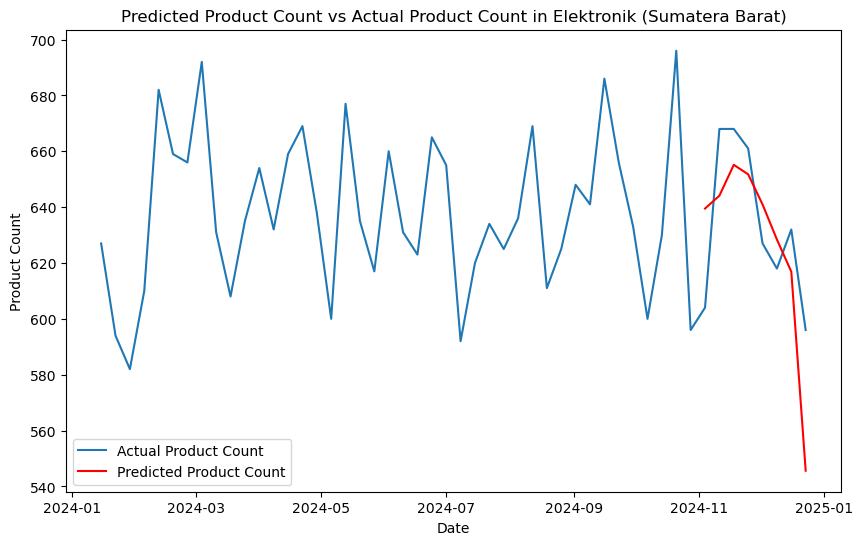

Root Mean Squared Error: 25.375527530838205


In [100]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Elektronik'
if decomposition_elektro_sumbar is not None:
    # Ambil dataset untuk kategori 'Elektronik'
    data_elektro = datasets_sumbar['Elektronik']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_elektro_sumbar.trend[-len(predictions_e):]
    seasonal_component = decomposition_elektro_sumbar.seasonal[-len(predictions_e):]
    predictions_product_count = trend_component + seasonal_component + predictions_e

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_elektro['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_elektro['product_count'].index, data_elektro['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Elektronik (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Elektronik' dataset.")

In [101]:
import pandas as pd

if decomposition_elektro_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_e_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_e_pred.head())

else:
    print("Warning: No decomposition results found for 'Elektronik' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   604                 639.493989
1 2024-11-11                   668                 644.104093
2 2024-11-18                   668                 655.148546
3 2024-11-25                   661                 651.744818
4 2024-12-02                   627                 640.979474


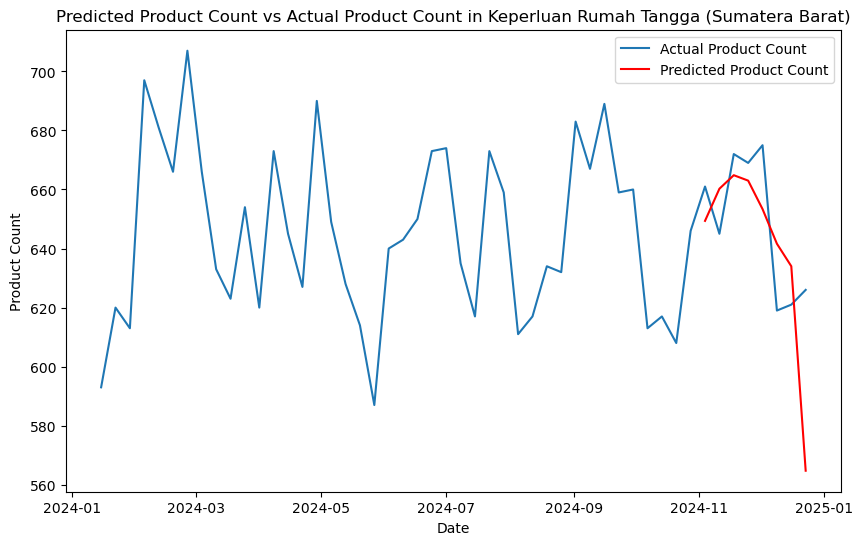

Root Mean Squared Error: 25.874176535202977


In [102]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Keperluan Rumah Tangga'
if decomposition_krt_sumbar is not None:
    # Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
    data_krt = datasets_sumbar['Keperluan Rumah Tangga']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_krt_sumbar.trend[-len(predictions_krt):]
    seasonal_component = decomposition_krt_sumbar.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_krt['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_krt['product_count'].index, data_krt['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Keperluan Rumah Tangga (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")

In [103]:
import pandas as pd

if decomposition_krt_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_krt_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_krt_pred.head())

else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   661                 649.371664
1 2024-11-11                   645                 660.256290
2 2024-11-18                   672                 664.839470
3 2024-11-25                   669                 663.001463
4 2024-12-02                   675                 653.365826


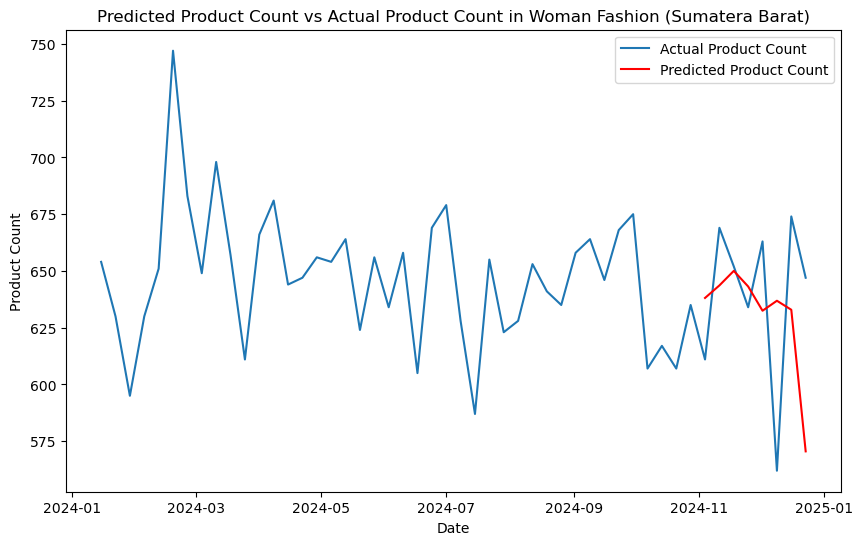

Root Mean Squared Error: 44.07589870805529


In [104]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_wf_sumbar is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_sumbar['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_wf_sumbar.trend[-len(predictions_wf):]
    seasonal_component = decomposition_wf_sumbar.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [105]:
import pandas as pd

if decomposition_wf_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   611                 638.098776
1 2024-11-11                   669                 643.619798
2 2024-11-18                   652                 650.024611
3 2024-11-25                   634                 643.147393
4 2024-12-02                   663                 632.473775


### 4. Undo Stationarity 3 Dataset berdasarkan produk dalam Maluku

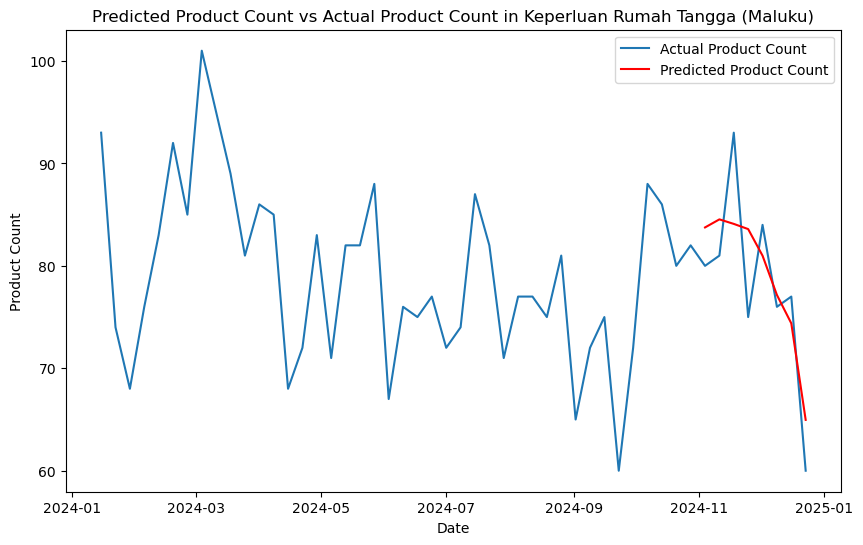

Root Mean Squared Error: 5.261419270789632


In [106]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Keperluan Rumah Tangga'
if decomposition_krt_maluku is not None:
    # Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
    data_krt = datasets_maluku['Keperluan Rumah Tangga']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_krt_maluku.trend[-len(predictions_krt):]
    seasonal_component = decomposition_krt_maluku.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_krt['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_krt['product_count'].index, data_krt['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Keperluan Rumah Tangga (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")

In [107]:
import pandas as pd

if decomposition_krt_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_krt_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_krt_pred.head())

else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    80                  83.749315
1 2024-11-11                    81                  84.536674
2 2024-11-18                    93                  84.094982
3 2024-11-25                    75                  83.587914
4 2024-12-02                    84                  80.993477


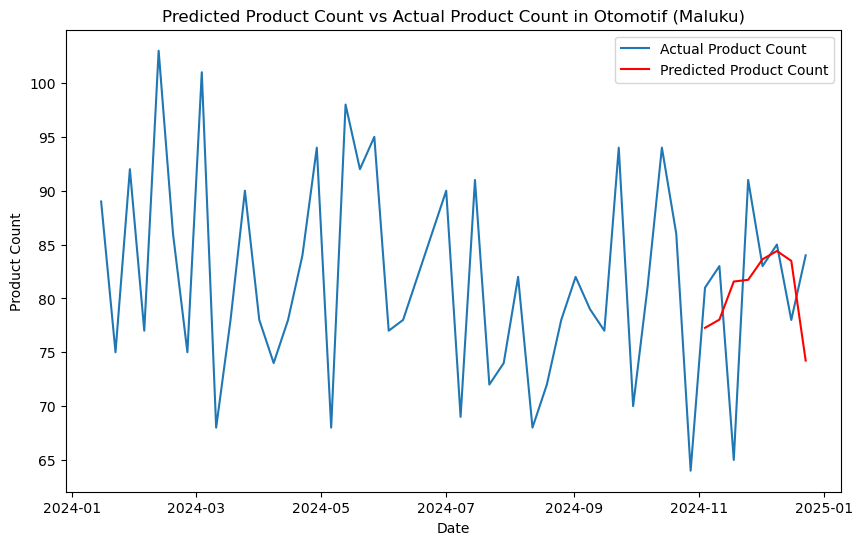

Root Mean Squared Error: 8.104579648560284


In [108]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Otomotif'
if decomposition_otomotif_maluku is not None:
    # Ambil dataset untuk kategori 'Otomotif'
    data_otomotif = datasets_maluku['Otomotif']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_otomotif_maluku.trend[-len(predictions_krt):]
    seasonal_component = decomposition_otomotif_maluku.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_otomotif['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_otomotif['product_count'].index, data_otomotif['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Otomotif (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Otomotif' dataset.")

In [109]:
import pandas as pd

if decomposition_otomotif_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_otomotif_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_otomotif_pred.head())

else:
    print("Warning: No decomposition results found for 'Otomotif' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    81                  77.267819
1 2024-11-11                    83                  78.031410
2 2024-11-18                    65                  81.568113
3 2024-11-25                    91                  81.726545
4 2024-12-02                    83                  83.636981


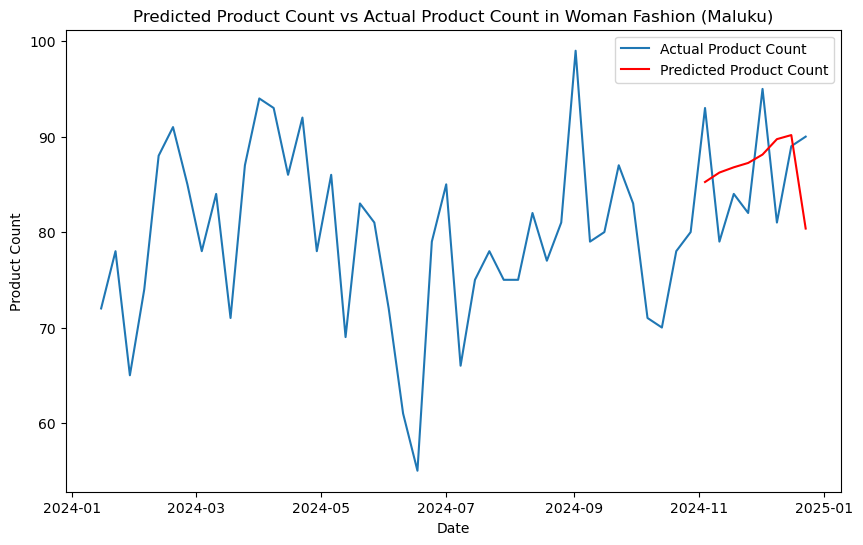

Root Mean Squared Error: 6.759189236562736


In [110]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_wf_maluku is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_maluku['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_wf_maluku.trend[-len(predictions_wf):]
    seasonal_component = decomposition_wf_maluku.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [111]:
import pandas as pd

if decomposition_wf_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    93                  85.247367
1 2024-11-11                    79                  86.236661
2 2024-11-18                    84                  86.788257
3 2024-11-25                    82                  87.243293
4 2024-12-02                    95                  88.122366


In [112]:
folder = 'kaggle_upload_forecast'
os.makedirs(folder, exist_ok=True)

dfs = {
    'jatim_fd_pred' : jatim_fd_pred,
    'jatim_mf_pred' : jatim_mf_pred,
    'jatim_rh_pred' : jatim_rh_pred,
    'sumut_fd_pred' : sumut_fd_pred,
    'sumut_rh_pred' : sumut_rh_pred,
    'sumut_wf_pred' : sumut_wf_pred,
    'sumbar_e_pred' : sumbar_e_pred,
    'sumbar_krt_pred' : sumbar_krt_pred,
    'sumbar_wf_pred' : sumbar_wf_pred,
    'maluku_krt_pred' : maluku_krt_pred,
    'maluku_otomotif_pred' : maluku_otomotif_pred,
    'maluku_wf_pred' : maluku_wf_pred
}

for name, df in dfs.items():
    df.to_csv(f'{folder}/{name}.csv', index=False)

print(os.listdir(folder))

['jatim_fd_pred.csv', 'jatim_mf_pred.csv', 'jatim_rh_pred.csv', 'maluku_krt_pred.csv', 'maluku_otomotif_pred.csv', 'maluku_wf_pred.csv', 'sumbar_e_pred.csv', 'sumbar_krt_pred.csv', 'sumbar_wf_pred.csv', 'sumut_fd_pred.csv', 'sumut_rh_pred.csv', 'sumut_wf_pred.csv']


In [113]:
metadata = {
    "title": "Forecasting Result Revenue",
    "id": "rebeccasihombing/forecasting-result-revenue",
    "licenses": [{"name": "CC0-1.0"}]
}

with open(f'{folder}/dataset-metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

api.dataset_create_new(folder=folder, dir_mode='zip')

Starting upload for file jatim_fd_pred.csv


100%|██████████| 337/337 [00:02<00:00, 152B/s]


Upload successful: jatim_fd_pred.csv (337B)
Starting upload for file jatim_mf_pred.csv


100%|██████████| 337/337 [00:01<00:00, 185B/s]


Upload successful: jatim_mf_pred.csv (337B)
Starting upload for file jatim_rh_pred.csv


100%|██████████| 337/337 [00:00<00:00, 341B/s]  


... (16 outputs left out)

Upload successful: sumut_rh_pred.csv (323B)
Starting upload for file sumut_wf_pred.csv


100%|██████████| 325/325 [00:00<00:00, 328B/s]  


Upload successful: sumut_wf_pred.csv (325B)


{"ref": "/datasets/rebeccasihombing/forecasting-result-revenue", "url": "https://www.kaggle.com/datasets/rebeccasihombing/forecasting-result-revenue", "status": "Ok", "error": null, "invalidTags": []}